# Minority game de tres decisiones: síntesis de resultados

**Tesis de licenciatura en Ingeniería Física (UADY)**
Autor: Héctor Quijano Munguía · Asesores: Dr. Ricardo Mansilla Corona (UNAM) y Dr. Saul J. Díaz Ceballos (UADY)

Este notebook reúne en un solo lugar lo más importante de todas las fases del trabajo. No sustituye a los notebooks de cada fase (que siguen en `notebooks/` y `resultados/`): toma su mismo código, sus mismos parámetros y sus mismas semillas, y vuelve a correr solo los casos más destacables. Por eso los números que salen aquí son **idénticos** a los de las fases originales.

No guarda ningún archivo: todas las gráficas se muestran dentro del notebook.

## Cómo usar este notebook

1. Corre **una vez** las celdas **1, 2 y 3** (configuración, motor del juego y medidas). Solo definen funciones y parámetros; tardan menos de un segundo.
2. Después puedes correr **cualquier sección por separado**, en el orden que quieras. Cada sección depende solo de las celdas 1 a 3.
3. Dentro de cada sección, la primera celda de código **simula** y guarda el resultado en memoria, en el diccionario `RESULTADOS`. Las celdas que siguen **solo grafican**: puedes cambiar una gráfica y volver a correrla sin volver a simular.

| Sección | Fases de origen | Tiempo aproximado de la simulación |
|---|---|---|
| 1. Tres tipos de agentes | 2 y 5 | menos de 1 min |
| 2. Conservadores y agresivos | 4 | menos de 1 min |
| 3. Variación del número de agentes | 3 y 6 | 1 a 2 min |
| 4. Variación de la memoria y juego binario | 7 y 8 | unos 11 min |
| 5. Precios y hechos estilizados | 9 | 2 a 3 min |
| 6. Búsqueda de la fase gaseosa | 11 | unos 4 min |
| 7. Ajuste de la función de Hill | 12 | unos 5 min |

Correr todo de principio a fin tarda unos 24 minutos. Los tiempos son de una computadora con 12 núcleos lógicos; las cadenas se reparten entre los núcleos con `joblib`, y el resultado es idéntico al de un solo núcleo.

## El modelo

Reglas acordadas con el Dr. Mansilla (8 de octubre de 2026):

- Hay **N agentes**. En cada turno cada uno elige una de **K = 3 opciones**: **0 = comprar**, **1 = vender**, **2 = abstenerse**. Abstenerse es una decisión propia, al mismo nivel que comprar y vender.
- N no es múltiplo de 3, para que nunca empaten las tres opciones.
- **Gana la opción menos elegida** (la minoría). Si las dos menos elegidas empatan, se decide con una moneda al aire (50 % cada una).
- El símbolo ganador se agrega a la **serie de resultados**, con alfabeto {0, 1, 2}. Esa serie es la que se analiza.
- Cada agente tiene **s estrategias**. Una estrategia es una tabla que, para cada una de las $K^m$ historias posibles de los últimos **m** resultados, dice qué opción elegir.
- **Con puntaje:** después de cada turno, todas las estrategias que habrían elegido la opción ganadora suman un punto virtual (se hayan usado o no), y cada agente juega con su estrategia de mayor puntaje (empates al azar).
- No hay burn-in: se registra desde el primer turno.

**Regla de la opción vacía.** Hay dos versiones, y aquí se elige con el parámetro `OPCION_VACIA_GANA` de la celda 1:

- `True` (**regla vieja**, la de `reglas_del_modelo.md` y de las fases 2 a 8 y 12): una opción con cero agentes también cuenta y puede ganar; en ese caso no gana ningún agente.
- `False` (**regla nueva**, la de las fases 9 y 11, pendiente de confirmar con el Dr. Mansilla): una opción vacía no cuenta; gana la menos elegida entre las que tienen al menos un agente, y si todos eligen lo mismo, gana esa opción.

Las dos reglas gastan los mismos números aleatorios, así que solo dan resultados distintos en las cadenas donde, en algún turno, una opción se queda sin agentes. **Con la regla vieja, este notebook reproduce exactamente todas las fases.** Las opciones vacías solo aparecen con pocos agentes: en la sección 3 hay turnos con una opción vacía para N ≤ 100 (el 22.5 % de los turnos con N = 5 y 73 de 600 000 con N = 50). En las secciones 5 y 6 y en los casos con estrategias de la sección 1 no hubo ninguno, y la fase 12 tampoco encontró ninguno en los casos con estrategias de la sección 7. Las secciones 2 y 4 no los cuentan. Si se cambia a la regla nueva, los resultados con pocos agentes cambiarían.

**Tipos de agentes** que aparecen en el notebook:

| Tipo | Cómo decide |
|---|---|
| Al azar (ingenuos, s = 0) | Elige 0, 1 o 2 con probabilidad 1/3, sin estrategias |
| Sin puntaje | Tiene s estrategias, pero no las califica: en cada turno usa una al azar |
| Con puntaje | Usa su estrategia con más puntos |
| Conservador | Con puntaje, pero si el 2 (abstenerse) ganó en más de la mitad de los últimos m turnos, se abstiene |
| Agresivo | Con puntaje, pero si el 1 (vender) ganó en más de la mitad de los últimos m turnos, vende |

> Nota: los notebooks más viejos dicen 0 = vender y 1 = comprar. Por la simetría del juego ningún número cambia; aquí se usan las etiquetas del protocolo.

## Las medidas

**Información mutua** (Mansilla, PRE 62, Ec. 6), en bits:

$$M(d)=\sum_{a,b}P_{ab}(d)\,\log_2\frac{P_{ab}(d)}{P_a\,P_b},\qquad d=1,\dots,100,$$

donde $P_{ab}(d)$ es la frecuencia de encontrar el símbolo $a$ y, $d$ lugares después, el símbolo $b$, y $P_a$ es la frecuencia del símbolo $a$ en toda la cadena. Mide cuánto sabemos del resultado $d$ turnos adelante si conocemos el de hoy. Una cadena sin correlación de largo $T$ no da cero, sino aproximadamente $(K-1)^2/(2T\ln 2)$: unos $4.8\times10^{-4}$ bits con $T=6000$ y $4.8\times10^{-5}$ con $T=60000$ (el **sesgo esperado**, línea punteada en las gráficas).

**Ajuste log-log:** se grafica $\log_{10}M(d)$ contra $\log_{10}d$ y se ajusta una recta (`np.polyfit` de grado 1) con todos los $d$; el único filtro es quitar los puntos con $M(d)=0$. Se reporta la pendiente y $R^2$.

**Complejidad física:** $C_K(l)=l\log_2K-H(l)$, donde $H(l)$ es la entropía de las subcadenas de longitud $l$. Vale 0 si todas las subcadenas aparecen con la misma frecuencia y crece con la estructura. La versión normalizada $c_K(l)=C_K(l)/(l\log_2K)$ permite comparar alfabetos de 2 y 3 símbolos.

**Parámetro de control:** $\gamma=K^m/N$, el número de historias posibles por agente.

**Espectro de potencias de $M(d)$** (protocolo, Ec. 4): $S(k)=\left|\sum_d M(d)\,e^{-2\pi i kd/L}\right|^2$. Los picos indican periodicidades en $M(d)$.

**Precios** (fase 9), con $N_0$ y $N_1$ el número de agentes que compran y venden:
- Mansilla: $p_t=\arctan(N_0/N_1)$.
- Exceso de demanda: $\ln p_{t+1}=\ln p_t+(N_0-N_1)/N$.
- Cociente: $\ln p_{t+1}=\ln p_t+\ln[(N_0+1)/(N_1+1)]/\ln(N+1)$.

**Función de Hill** (fase 12, script del Dr. Mansilla): $H(x)=A+\dfrac{B}{1+(x/C)^{\alpha}}$, ajustada a $y=\log_{10}M(d)$ contra $x=\log_{10}d$. $A$ es el nivel para $d$ grande, $A+B$ el nivel en $d=1$, $C$ el $\log_{10}d$ donde ocurre la mitad de la caída y $\alpha$ qué tan brusca es.

Todas las medidas se calculan por cadena y se promedian sobre **100 cadenas** (100 semillas distintas). Los intervalos son del 95 % con $t$ de Student.

---
## Celda 1. Configuración

Librerías, opciones y las 100 semillas. Si cambias algo aquí, vuelve a correr las celdas 1 a 3.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from joblib import Parallel, delayed
from scipy.stats import t as t_student
from scipy.optimize import least_squares
from scipy.special import expit
import itertools

# ---------------------------------------------------------------------
# OPCIONES
# ---------------------------------------------------------------------
OPCION_VACIA_GANA = True   # True = regla vieja (una opcion vacia puede ganar); False = regla nueva
N_NUCLEOS = -1             # -1 = todos los nucleos; 1 = un solo nucleo (mismo resultado, mas lento)

# ---------------------------------------------------------------------
# PARAMETROS COMUNES A TODAS LAS SECCIONES
# ---------------------------------------------------------------------
SEMILLA_MAESTRA = 1907443528
N_CADENAS = 100
SEMILLAS = np.random.SeedSequence(SEMILLA_MAESTRA).generate_state(N_CADENAS)   # las mismas de todas las fases

D_MAX = 100                       # M(d) con d = 1, ..., 100
DISTANCIAS = np.arange(1, D_MAX + 1)
L_MAX = 6                         # C_K(l) con l = 1, ..., 6
NIVEL = 0.95                      # intervalo de confianza

RESULTADOS = {}                   # aqui guarda cada seccion lo que simula

# Estilo de las graficas
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORES = ["#2a78d6", "#e8613c", "#1aa37a", "#9b59b6", "#f0a020", "#555555", "#c0392b", "#16a0b5", "#7f8c2a"]

print(f"Regla: {'vieja (una opcion vacia puede ganar)' if OPCION_VACIA_GANA else 'nueva (una opcion vacia no cuenta)'}")
print(f"{N_CADENAS} cadenas, semilla maestra {SEMILLA_MAESTRA}")

Regla: vieja (una opcion vacia puede ganar)
100 cadenas, semilla maestra 1907443528


## Celda 2. Motor del juego

Las funciones que juegan el minority game. Son las mismas de los notebooks de las fases (las de la fase 9, que agregan el registro de cuántos agentes eligen cada opción), sin cambios en la forma en que usan los números aleatorios. Esta celda solo define funciones.

In [2]:
def regla_ganador(conteos, rng, opcion_vacia_gana):
    """Devuelve la opcion ganadora y si se decidio con moneda.

    Regla vieja: gana el minimo de las K opciones (una vacia cuenta).
    Regla nueva: gana el minimo entre las opciones con al menos un agente.
    El desempate usa rng.choice; las dos reglas gastan los mismos numeros aleatorios.
    """
    if opcion_vacia_gana:
        minimo = conteos.min()
    else:
        minimo = conteos[conteos > 0].min()
    empatados = np.flatnonzero(conteos == minimo)
    return int(rng.choice(empatados)), len(empatados) > 1


def simular_ingenuos(N, m, K, T, semilla, opcion_vacia_gana):
    """Agentes que eligen al azar (s = 0). La memoria se lleva igual que en el
    juego con estrategias, aunque nadie la consulta. Devuelve la serie de ganadores."""
    rng = np.random.default_rng(semilla)
    historia = rng.integers(0, K, size=m)
    serie_ganadores = np.zeros(T, dtype=int)
    for t in range(T):
        acciones = rng.integers(0, K, size=N)              # cada agente elige al azar
        conteos = np.bincount(acciones, minlength=K)
        ganador, _ = regla_ganador(conteos, rng, opcion_vacia_gana)
        serie_ganadores[t] = ganador
        historia = np.roll(historia, -1)
        historia[-1] = ganador
    return serie_ganadores


def simular_sin_recompensa(N, m, s, K, T, semilla, opcion_vacia_gana):
    """Agentes con s estrategias que no las califican: los puntajes valen siempre 0,
    asi que en cada turno cada agente usa al azar una de sus estrategias.
    Devuelve la serie de ganadores, los conteos (N0, N1, N2) y si hubo moneda."""
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))   # estrategias[i, j, h]
    puntajes = np.zeros((N, s))
    historia = rng.integers(0, K, size=m)
    pesos = K ** np.arange(m - 1, -1, -1)                    # historia -> indice
    indices = np.arange(N)
    serie_ganadores = np.zeros(T, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)
    con_moneda = np.zeros(T, dtype=bool)
    for t in range(T):
        idx = int(historia @ pesos)
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)   # todo empatado: al azar
        acciones = estrategias[indices, mejor, idx]
        conteos = np.bincount(acciones, minlength=K)
        ganador, hubo_moneda = regla_ganador(conteos, rng, opcion_vacia_gana)
        serie_ganadores[t] = ganador
        conteos_por_turno[t] = conteos
        con_moneda[t] = hubo_moneda
        historia = np.roll(historia, -1)
        historia[-1] = ganador
    return serie_ganadores, conteos_por_turno, con_moneda


def simular_con_puntaje(N, m, s, K, T, semilla, opcion_vacia_gana):
    """El juego con puntaje. Devuelve la serie de ganadores, cuantas veces acerto
    cada agente, los conteos (N0, N1, N2) de cada turno y si hubo moneda."""
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))   # estrategias[i, j, h]
    puntajes = np.zeros((N, s))                              # puntos virtuales
    historia = rng.integers(0, K, size=m)                    # memoria inicial
    pesos = K ** np.arange(m - 1, -1, -1)
    indices = np.arange(N)
    serie_ganadores = np.zeros(T, dtype=int)
    conteos_por_turno = np.zeros((T, K), dtype=np.int32)
    con_moneda = np.zeros(T, dtype=bool)
    exitos_agente = np.zeros(N, dtype=int)
    for t in range(T):
        idx = int(historia @ pesos)                                        # 1. historia actual
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)     # 2. mejor estrategia (empates al azar)
        acciones = estrategias[indices, mejor, idx]                        # 3. cada agente actua
        conteos = np.bincount(acciones, minlength=K)                       # 4. conteo
        ganador, hubo_moneda = regla_ganador(conteos, rng, opcion_vacia_gana)   # 5. gana la minoria
        puntajes += (estrategias[:, :, idx] == ganador)                    # 6. puntos a las que acertaron
        serie_ganadores[t] = ganador                                       # 7. registro
        conteos_por_turno[t] = conteos
        con_moneda[t] = hubo_moneda
        exitos_agente += (acciones == ganador)
        historia = np.roll(historia, -1)                                   # 8. la memoria avanza
        historia[-1] = ganador
    return serie_ganadores, exitos_agente, conteos_por_turno, con_moneda


def historias_con_simbolo(m, K, simbolo, min_veces):
    """Indices de las historias donde 'simbolo' aparece al menos min_veces."""
    indices = []
    for h in range(K ** m):
        digitos = [(h // K ** (m - 1 - p)) % K for p in range(m)]
        if digitos.count(simbolo) >= min_veces:
            indices.append(h)
    return np.array(indices, dtype=int)


def simular_con_tipos(N, m, s, K, T, n_cons, n_agr, semilla, opcion_vacia_gana,
                      accion_cons=2, accion_agr=1, semilla_tipos=2024):
    """Juego con puntaje con n_cons conservadores y n_agr agresivos (fase 4).

    Conservadores: en las historias con mas de un 2, sus dos estrategias dicen 2.
    Agresivos: en las historias con mas de un 1, sus dos estrategias dicen 1.
    Quien es de cada tipo se elige con un generador aparte (no mueve la secuencia
    principal): los conservadores son los primeros de una permutacion y los
    agresivos los ultimos. Devuelve la serie, los aciertos y las mascaras de tipo."""
    rng = np.random.default_rng(semilla)
    N_HIST = K ** m
    estrategias = rng.integers(0, K, size=(N, s, N_HIST))
    rng_tipos = np.random.default_rng([semilla, semilla_tipos])
    orden = rng_tipos.permutation(N)
    es_cons = np.zeros(N, dtype=bool)
    es_agr = np.zeros(N, dtype=bool)
    es_cons[orden[:n_cons]] = True
    if n_agr > 0:
        es_agr[orden[N - n_agr:]] = True
    if n_cons > 0:
        estrategias[np.ix_(es_cons, np.arange(s), historias_con_simbolo(m, K, accion_cons, 2))] = accion_cons
    if n_agr > 0:
        estrategias[np.ix_(es_agr, np.arange(s), historias_con_simbolo(m, K, accion_agr, 2))] = accion_agr
    puntajes = np.zeros((N, s))
    historia = rng.integers(0, K, size=m)
    pesos = K ** np.arange(m - 1, -1, -1)
    indices = np.arange(N)
    serie_ganadores = np.zeros(T, dtype=int)
    exitos_agente = np.zeros(N, dtype=int)
    for t in range(T):
        idx = int(historia @ pesos)
        mejor = np.argmax(puntajes + rng.random((N, s)) * 0.5, axis=1)
        acciones = estrategias[indices, mejor, idx]
        conteos = np.bincount(acciones, minlength=K)
        ganador, _ = regla_ganador(conteos, rng, opcion_vacia_gana)
        puntajes += (estrategias[:, :, idx] == ganador)
        serie_ganadores[t] = ganador
        exitos_agente += (acciones == ganador)
        historia = np.roll(historia, -1)
        historia[-1] = ganador
    return serie_ganadores, exitos_agente, es_cons, es_agr


def correr_en_paralelo(funcion, tareas):
    """Corre funcion(*tarea) para cada tarea repartiendo entre nucleos.
    El resultado es identico al de un solo nucleo."""
    if N_NUCLEOS == 1:
        return [funcion(*tarea) for tarea in tareas]
    return Parallel(n_jobs=N_NUCLEOS)(delayed(funcion)(*tarea) for tarea in tareas)


print("Motor del juego listo.")

Motor del juego listo.


## Celda 3. Medidas, ajustes y precios

Información mutua, complejidad física, espectro, ajustes log-log, precios, hechos estilizados y la función de Hill. Las funciones `hill` y `ajustar_hill` son las del script `ajuste_hill.py` del Dr. Mansilla, con el mismo código; solo se acortaron sus comentarios. Esta celda solo define funciones.

In [3]:
# ---------------------------------------------------------------------
# Informacion mutua, complejidad y espectro
# ---------------------------------------------------------------------
def informacion_mutua(serie, d, K):
    """M(d) = sum_ab P_ab(d) log2[P_ab(d) / (P_a P_b)]  (Mansilla, PRE 62, Ec. 6).
    P_ab(d) se estima con todos los pares (serie[i], serie[i+d]); P_a es la
    frecuencia del simbolo a en toda la cadena."""
    x, y = serie[:-d], serie[d:]
    conjunta = np.bincount(x * K + y, minlength=K * K).reshape(K, K) / len(x)
    densidad = np.bincount(serie, minlength=K) / len(serie)
    producto = np.outer(densidad, densidad)
    M_d = 0.0
    for a in range(K):
        for b in range(K):
            if conjunta[a, b] > 0:
                M_d += conjunta[a, b] * np.log2(conjunta[a, b] / producto[a, b])
    return M_d


def M_de_serie(serie, K):
    """M(d) para d = 1, ..., D_MAX."""
    return np.array([informacion_mutua(serie, d, K) for d in DISTANCIAS])


def complejidad_fisica(serie, l, K):
    """Devuelve C_K(l) = l log2 K - H(l) y su version normalizada c_K(l)."""
    ventanas = np.lib.stride_tricks.sliding_window_view(serie, l)
    codigos = ventanas @ (K ** np.arange(l - 1, -1, -1))
    conteos = np.bincount(codigos, minlength=K ** l)
    p = conteos[conteos > 0] / len(codigos)
    H = -np.sum(p * np.log2(p))
    maximo = l * np.log2(K)
    return maximo - H, (maximo - H) / maximo


def C_de_serie(serie, K, l_max=L_MAX):
    """C_K(l) para l = 1, ..., l_max."""
    return np.array([complejidad_fisica(serie, l, K)[0] for l in range(1, l_max + 1)])


def sesgo_esperado(K, n_pares):
    """M(d) de una cadena SIN correlacion, solo por ser finita."""
    return (K - 1) ** 2 / (2 * n_pares * np.log(2))


def espectro_potencias(Md):
    """Ec. 4 del protocolo con u = 1. Devuelve la frecuencia k/L y S(k), k = 1..L/2."""
    L = len(Md)
    d = np.arange(1, L + 1)
    k = np.arange(1, L // 2 + 1)
    return k / L, np.abs(np.exp(-2j * np.pi * np.outer(k, d) / L) @ Md) ** 2


def contraste(Md, d0, vecinos=7):
    """Cuanto sobresale M(d0): M(d0) entre la mediana de sus 14 vecinos.
    1 = no hay pico; el umbral acordado para hablar de pico es 2."""
    cerca = [d for d in range(d0 - vecinos, d0 + vecinos + 1) if d != d0 and 1 <= d <= len(Md)]
    return Md[d0 - 1] / np.median(Md[np.array(cerca) - 1])


def exito_al_azar(N, K, n_muestras=200000, semilla=0):
    """Tasa de exito que tendrian N agentes eligiendo al azar."""
    rng = np.random.default_rng(semilla)
    conteos = rng.multinomial(N, [1 / K] * K, size=n_muestras)
    return (conteos.min(axis=1) / N).mean()


def promedio_ic(tabla):
    """Media sobre las cadenas (filas) e intervalo de confianza del 95 %."""
    tabla = np.asarray(tabla, dtype=float)
    n = tabla.shape[0]
    media = tabla.mean(axis=0)
    error = tabla.std(axis=0, ddof=1) / np.sqrt(n)
    t_crit = t_student.ppf((1 + NIVEL) / 2, n - 1)
    return media, media - t_crit * error, media + t_crit * error


# ---------------------------------------------------------------------
# Ajustes
# ---------------------------------------------------------------------
def ajuste_loglog(x, y):
    """Recta en log10 y contra log10 x. UNICO filtro: se quitan los puntos con y <= 0."""
    validos = y > 0
    lx, ly = np.log10(x[validos]), np.log10(y[validos])
    pendiente, ordenada = np.polyfit(lx, ly, 1)
    y_ajuste = ordenada + pendiente * lx
    r2 = 1 - np.sum((ly - y_ajuste) ** 2) / np.sum((ly - ly.mean()) ** 2)
    return {"pendiente": pendiente, "ordenada": ordenada, "r2": r2, "x": lx, "y": ly,
            "y_ajuste": y_ajuste, "n_puntos": int(validos.sum())}


def ajuste_potencia(longitudes, C, l_min=2):
    """C(l) = beta * l^alpha, recta en log-log con l >= l_min (fase 9)."""
    usar = (longitudes >= l_min) & (C > 0)
    x, y = np.log10(longitudes[usar]), np.log10(C[usar])
    alpha, ordenada = np.polyfit(x, y, 1)
    r2 = 1 - np.sum((y - (alpha * x + ordenada)) ** 2) / np.sum((y - y.mean()) ** 2)
    return {"alpha": alpha, "beta": 10 ** ordenada, "r2": r2}


# --- Funcion de Hill: mismo codigo que ajuste_hill.py (Dr. Mansilla); solo se acortaron los comentarios ---
def hill(x, A, B, C, alfa):
    """Calcula H(x) = A + B / (1 + (x/C)**alfa)."""
    x = np.asarray(x, dtype=float)
    if not np.isfinite(x).all() or np.any(x < 0):
        raise ValueError("La función necesita valores finitos de x >= 0.")
    if not (np.isfinite([A, B, C, alfa]).all() and C > 0 and alfa > 0):
        raise ValueError("A y B deben ser finitos; C y alfa deben ser positivos.")
    logx = np.full(x.shape, -np.inf)
    np.log(x, out=logx, where=x > 0)
    return A + B * expit(-alfa * (logx - np.log(C)))


def ajustar_hill(x, y, inicios=30, semilla=12345, alfa_min=0.01,
                 alfa_max=100.0, c_min=None, c_max=None):
    """Estima A, B, C y alfa minimizando suma((y - H(x))**2)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    if x.ndim != 1 or y.ndim != 1 or x.size != y.size:
        raise ValueError("x e y deben ser vectores de igual longitud.")
    if x.size < 5 or np.unique(x).size < 4:
        raise ValueError("Se requieren al menos 5 pares y 4 valores distintos de x.")
    if not np.isfinite(x).all() or not np.isfinite(y).all() or np.any(x < 0):
        raise ValueError("Se necesitan pares finitos y x >= 0. No se desplaza ni transforma x.")
    if inicios < 1 or not (0 < alfa_min < alfa_max < np.inf):
        raise ValueError("Use inicios >= 1 y 0 < alfa_min < alfa_max finitos.")
    positivos = x[x > 0]
    c_min = float(positivos.min() / 1000) if c_min is None else float(c_min)
    c_max = float(x.max() * 1000) if c_max is None else float(c_max)
    if not (0 < c_min < c_max < np.inf):
        raise ValueError("Los límites de C deben ser finitos y satisfacer 0 < c_min < c_max.")
    centro, escala = float(np.mean(y)), float(np.std(y))
    if not np.isfinite(escala) or escala <= np.finfo(float).eps * max(float(np.max(abs(y))), np.finfo(float).tiny):
        raise ValueError("y es constante o no tiene variación numérica suficiente para identificar cuatro parámetros.")
    yn = (y - centro) / escala
    logx = np.full(x.shape, -np.inf)
    np.log(x, out=logx, where=x > 0)
    inferior = np.log([c_min, alfa_min])
    superior = np.log([c_max, alfa_max])

    def proyectar(z):
        """Para z = (log(C), log(alfa)), resuelve A y B en escala normalizada."""
        g = expit(-np.exp(z[1]) * (logx - z[0]))
        matriz = np.column_stack((np.ones(x.size), g))
        ab, _, _, _ = np.linalg.lstsq(matriz, yn, rcond=None)
        return matriz @ ab - yn, ab, g

    rng = np.random.default_rng(semilla)
    centros = np.quantile(np.log(positivos), np.linspace(0, 1, 6))
    exponentes = np.log(np.array([0.3, 1, 3, 10, 30]))
    candidatos = [np.clip(np.array(z), inferior + 1e-8, superior - 1e-8)
                  for z in itertools.product(centros, exponentes)]
    rng.shuffle(candidatos)
    while len(candidatos) < inicios:
        candidatos.append(rng.uniform(inferior, superior))
    soluciones = []
    for z0 in candidatos[:inicios]:
        ajuste = least_squares(lambda z: proyectar(z)[0], z0,
                               bounds=(inferior, superior), max_nfev=4000,
                               ftol=1e-11, xtol=1e-11, gtol=1e-11)
        if ajuste.success and np.isfinite(ajuste.fun).all():
            soluciones.append(ajuste)
    if not soluciones:
        raise ValueError("Ningún ajuste convergió. Revise los datos y los límites de C y alfa.")
    mejor = min(soluciones, key=lambda s: float(s.fun @ s.fun))
    _, ab, g = proyectar(mejor.x)
    A, B = float(centro + escala * ab[0]), float(escala * ab[1])
    C, alfa = (float(v) for v in np.exp(mejor.x))
    prediccion = hill(x, A, B, C, alfa)
    residuos = y - prediccion
    sse = float(residuos @ residuos)
    sst = float((y - centro) @ (y - centro))
    avisos = []
    if np.any((mejor.x - inferior < 1e-4) | (superior - mejor.x < 1e-4)):
        avisos.append("C o alfa está junto a un límite de búsqueda; amplíe los límites y compare el resultado.")
    w = g * (1 - g)
    derivada_alfa = np.zeros(x.size)
    mascara = x > 0
    derivada_alfa[mascara] = -ab[1] * alfa * (logx[mascara] - np.log(C)) * w[mascara]
    jac = np.column_stack((np.ones(x.size), g, ab[1] * alfa * w, derivada_alfa))
    singular = np.linalg.svd(jac, compute_uv=False)
    condicion = float(singular[0] / singular[-1]) if singular[-1] > 0 else np.inf
    if condicion > 1e8:
        avisos.append("Los datos identifican débilmente algunos parámetros: combinaciones diferentes pueden dar curvas similares.")
    return {
        "modelo": "H(x) = A + B / (1 + (x/C)^alfa)",
        "coeficientes": {"A": A, "B": B, "C": C, "alfa": alfa},
        "n": int(x.size), "R2": float(1 - sse / sst),
        "RMSE": float(np.sqrt(sse / x.size)), "SSE": sse,
        "criterio": "Minimizar la suma de (y - H(x))^2; igual peso por par; sin transformar x ni y",
        "inicios": int(inicios), "inicios_convergentes": len(soluciones),
        "semilla": int(semilla), "limites": {"C": [c_min, c_max], "alfa": [alfa_min, alfa_max]},
        "condicion_jacobiano_normalizado": condicion if np.isfinite(condicion) else None,
        "avisos": avisos,
    }


# ---------------------------------------------------------------------
# Precios y hechos estilizados (fase 9)
# ---------------------------------------------------------------------
def precio_mansilla(N0, N1):
    """p_t = arctan(N0/N1). Si N0 = N1 = 0 se repite el precio anterior (pi/4 al inicio)."""
    p = np.arctan2(N0, N1).astype(float)
    for t in np.flatnonzero((N0 == 0) & (N1 == 0)):
        p[t] = p[t - 1] if t > 0 else np.pi / 4
    return p


def rendimientos_y_signo(precio, N0, N1, N):
    """Rendimiento r_t de un precio y el signo exacto de su cambio (+1, 0, -1).
    Mansilla: r_t = ln p_t - ln p_{t-1}. Exceso y cociente: el incremento de ln p."""
    if precio == "mansilla":
        p = precio_mansilla(N0.astype(float), N1.astype(float))
        a, b = N0.copy(), N1.copy()
        for t in np.flatnonzero((a == 0) & (b == 0)):
            a[t], b[t] = (a[t - 1], b[t - 1]) if t > 0 else (1, 1)
        return np.diff(np.log(p)), np.sign(a[1:] * b[:-1] - a[:-1] * b[1:])
    if precio == "exceso":
        return (N0 - N1) / N, np.sign(N0 - N1)
    return np.log((N0 + 1) / (N1 + 1)) / np.log(N + 1), np.sign(N0 - N1)


def curtosis(r):
    """Curtosis en exceso: 0 para una normal, > 0 con colas anchas."""
    x = r - r.mean()
    varianza = np.mean(x ** 2)
    return np.mean(x ** 4) / varianza ** 2 - 3 if varianza > 0 else np.nan


def exponente_cola(r, fraccion=0.05):
    """Estimador de Hill del exponente de la cola de |r - media| con el 5 % mas grande.
    Un valor chico indica colas anchas. (No tiene relacion con la funcion de Hill.)"""
    x = np.sort(np.abs(r - r.mean()))[::-1]
    k = max(int(fraccion * len(x)), 10)
    if x[k] <= 0:
        return np.nan
    suma = np.sum(np.log(x[:k] / x[k]))
    return k / suma if suma > 0 else np.nan


def autocorrelacion(x, lag_max=100):
    """Autocorrelacion de x para los retardos 1, ..., lag_max."""
    x = x - x.mean()
    varianza = x @ x
    if varianza == 0:
        return np.full(lag_max, np.nan)
    return np.array([x[:-k] @ x[k:] for k in range(1, lag_max + 1)]) / varianza


print("Medidas y ajustes listos.")

Medidas y ajustes listos.


---
# Sección 1. Tres tipos de agentes (fases 2 y 5)

**Pregunta:** ¿la serie de resultados tiene memoria? ¿Depende de cómo deciden los agentes?

Se comparan tres formas de decidir con los mismos parámetros: N = 50, m = 3, s = 2, T = 6000. Los agentes al azar son la referencia: su serie no debería tener ninguna correlación. Después se pasa $M(d)$ a escala log-log y se ajusta una recta (fase 5).

In [4]:
# ===== SECCION 1: simulacion =====
P1 = {"N": 50, "m": 3, "s": 2, "K": 3, "T": 6000}
CASOS_1 = {"ingenuos": "Agentes al azar (ingenuos)",
           "sin_puntaje": "2 estrategias sin puntaje",
           "con_puntaje": "2 estrategias con puntaje"}


def cadena_1(caso, semilla):
    N, m, s, K, T = P1["N"], P1["m"], P1["s"], P1["K"], P1["T"]
    if caso == "ingenuos":
        serie = simular_ingenuos(N, m, K, T, semilla, OPCION_VACIA_GANA)
    elif caso == "sin_puntaje":
        serie = simular_sin_recompensa(N, m, s, K, T, semilla, OPCION_VACIA_GANA)[0]
    else:
        serie = simular_con_puntaje(N, m, s, K, T, semilla, OPCION_VACIA_GANA)[0]
    return M_de_serie(serie, K)


t0 = time.time()
tareas = [(caso, int(sem)) for caso in CASOS_1 for sem in SEMILLAS]
salida = correr_en_paralelo(cadena_1, tareas)
RESULTADOS["S1"] = {caso: np.array(salida[i * N_CADENAS:(i + 1) * N_CADENAS]) for i, caso in enumerate(CASOS_1)}
print(f"Seccion 1 lista en {time.time() - t0:.0f} s: 3 casos x {N_CADENAS} cadenas, N={P1['N']}, m={P1['m']}, s={P1['s']}, T={P1['T']}")

Seccion 1 lista en 12 s: 3 casos x 100 cadenas, N=50, m=3, s=2, T=6000


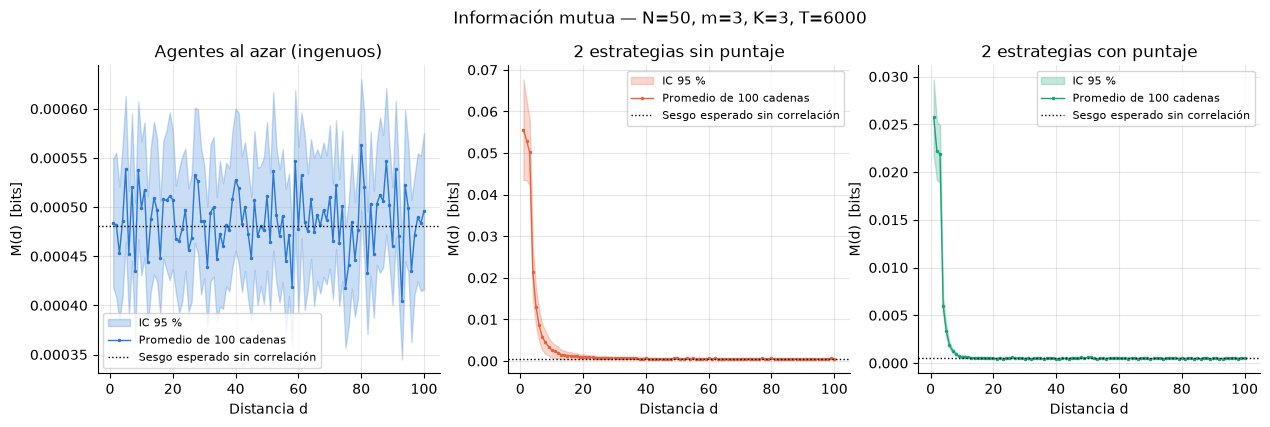

In [5]:
# ===== SECCION 1: M(d) promedio con su intervalo de confianza =====
fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sesgo = sesgo_esperado(P1["K"], P1["T"])
for ax, (caso, nombre), color in zip(ejes, CASOS_1.items(), COLORES):
    media, inf, sup = promedio_ic(RESULTADOS["S1"][caso])
    ax.fill_between(DISTANCIAS, inf, sup, color=color, alpha=0.25, label="IC 95 %")
    ax.plot(DISTANCIAS, media, ".-", color=color, ms=3, lw=1, label="Promedio de 100 cadenas")
    ax.axhline(sesgo, color="k", ls=":", lw=1, label="Sesgo esperado sin correlación")
    ax.set(title=nombre, xlabel="Distancia d", ylabel="M(d)  [bits]")
    ax.legend(fontsize=8)
fig.suptitle(f"Información mutua — N={P1['N']}, m={P1['m']}, K=3, T={P1['T']}", y=1.02)
plt.show()

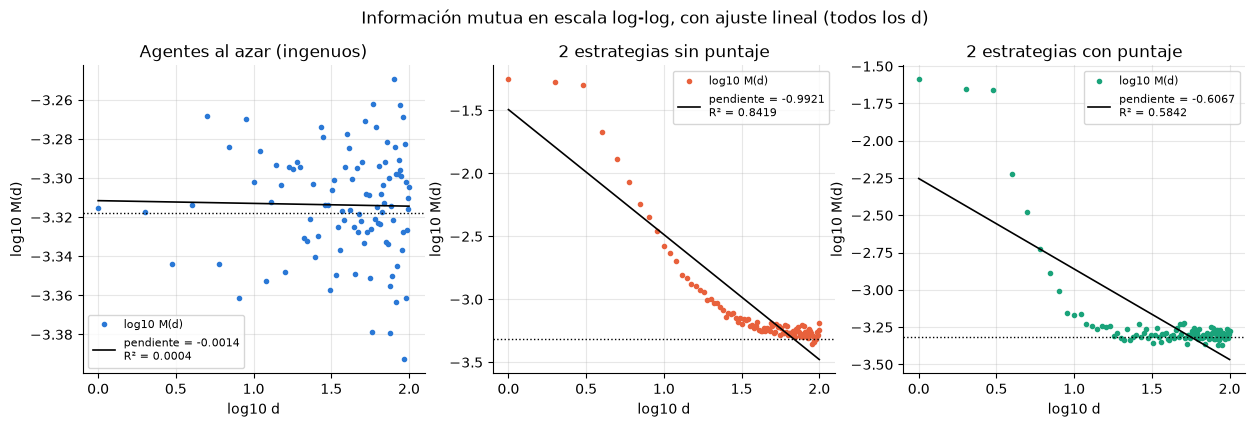

| Caso | Pendiente | R² | Pendiente de referencia | R² de referencia |
|---|---|---|---|---|
| Agentes al azar (ingenuos) | -0.0014 | 0.0004 | -0.0014 | 0.0004 |
| 2 estrategias sin puntaje | -0.9921 | 0.8419 | -0.9921 | 0.8419 |
| 2 estrategias con puntaje | -0.6067 | 0.5842 | -0.6067 | 0.5842 |

In [6]:
# ===== SECCION 1: escala log-log y ajuste lineal (fase 5) =====
# Valores de referencia de CLAUDE.md (fase 5.1) para comprobar que todo se reproduce
REFERENCIA_1 = {"ingenuos": (-0.0014, 0.0004), "sin_puntaje": (-0.9921, 0.8419), "con_puntaje": (-0.6067, 0.5842)}
sesgo = sesgo_esperado(P1["K"], P1["T"])

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
filas = []
for ax, (caso, nombre), color in zip(ejes, CASOS_1.items(), COLORES):
    media = RESULTADOS["S1"][caso].mean(axis=0)
    aj = ajuste_loglog(DISTANCIAS, media)
    ax.plot(aj["x"], aj["y"], "o", color=color, ms=3, label="log10 M(d)")
    ax.plot(aj["x"], aj["y_ajuste"], "k-", lw=1.2, label=f"pendiente = {aj['pendiente']:.4f}\nR² = {aj['r2']:.4f}")
    ax.axhline(np.log10(sesgo), color="k", ls=":", lw=1)
    ax.set(title=nombre, xlabel="log10 d", ylabel="log10 M(d)")
    ax.legend(fontsize=8)
    filas.append(f"| {nombre} | {aj['pendiente']:.4f} | {aj['r2']:.4f} | {REFERENCIA_1[caso][0]:.4f} | {REFERENCIA_1[caso][1]:.4f} |")
fig.suptitle("Información mutua en escala log-log, con ajuste lineal (todos los d)", y=1.02)
plt.show()
display(Markdown("| Caso | Pendiente | R² | Pendiente de referencia | R² de referencia |\n|---|---|---|---|---|\n" + "\n".join(filas)))

**Qué se observa**

- **Agentes al azar:** $M(d)$ es plana y queda en el nivel del sesgo esperado ($\approx 5\times10^{-4}$ bits): la serie no tiene memoria. La recta tiene pendiente prácticamente cero.
- **Con estrategias** (con o sin puntaje), $M(d)$ es mucho mayor para $d$ chica y decae con $d$: los resultados de un turno dan información sobre los siguientes. Es la memoria que introducen las estrategias.
- En log-log, la caída sin puntaje es más pronunciada (pendiente cercana a $-1$) que con puntaje (cercana a $-0.6$). En los dos casos la recta describe solo en parte la curva ($R^2$ de 0.84 y 0.58).
- La tabla compara las pendientes con los valores de referencia de la fase 5: coinciden.

---
# Sección 2. Conservadores y agresivos (fase 4)

**Pregunta:** ¿qué pasa si una parte de los agentes sigue la tendencia reciente?

Partiendo del caso con puntaje de la sección 1 (N = 50, m = 3, s = 2, T = 6000), una fracción de 30 % de los agentes recibe una regla fija:

- **Conservadores:** en las historias donde el 2 (abstenerse) aparece más de una vez (con m = 3: 022, 122, 202, 212, 220, 221, 222), sus dos estrategias dicen 2.
- **Agresivos:** igual, con el 1 (vender): 011, 101, 110, 111, 112, 121, 211.
- **Combinados:** 30 % de conservadores y 30 % de agresivos (60 % de agentes especiales).

Con 30 % de 50 hay 15 agentes de cada tipo. Se incluye el caso sin agentes especiales como referencia. Es la corrida del 19/10 para N = 50 y 30 %.

In [7]:
# ===== SECCION 2: simulacion =====
P2 = {"N": 50, "m": 3, "s": 2, "K": 3, "T": 6000, "fraccion": 0.30}
n_tipo = int(np.floor(P2["fraccion"] * P2["N"] + 0.5))     # 15 agentes
TIPOS_2 = {"sin_especiales": ("Sin agentes especiales", 0, 0),
           "conservadores": ("Solo conservadores", n_tipo, 0),
           "agresivos": ("Solo agresivos", 0, n_tipo),
           "combinados": ("Combinados", n_tipo, n_tipo)}


def cadena_2(n_cons, n_agr, semilla):
    N, m, s, K, T = P2["N"], P2["m"], P2["s"], P2["K"], P2["T"]
    serie, exitos, es_cons, es_agr = simular_con_tipos(N, m, s, K, T, n_cons, n_agr, semilla, OPCION_VACIA_GANA)
    es_com = ~(es_cons | es_agr)
    tasa = lambda mascara: exitos[mascara].sum() / (mascara.sum() * T) if mascara.sum() > 0 else np.nan
    return M_de_serie(serie, K), np.bincount(serie, minlength=K) / T, tasa(es_cons), tasa(es_agr), tasa(es_com)


t0 = time.time()
tareas = [(nc, na, int(sem)) for _, nc, na in TIPOS_2.values() for sem in SEMILLAS]
salida = correr_en_paralelo(cadena_2, tareas)
RESULTADOS["S2"] = {}
for i, clave in enumerate(TIPOS_2):
    bloque = salida[i * N_CADENAS:(i + 1) * N_CADENAS]
    RESULTADOS["S2"][clave] = {
        "Md": np.array([b[0] for b in bloque]),
        "frec": np.mean([b[1] for b in bloque], axis=0),
        "exito": [np.nanmean([b[j] for b in bloque]) if not np.all(np.isnan([b[j] for b in bloque])) else np.nan
                  for j in (2, 3, 4)]}
print(f"Seccion 2 lista en {time.time() - t0:.0f} s: {len(TIPOS_2)} casos x {N_CADENAS} cadenas, {n_tipo} agentes de cada tipo")

Seccion 2 lista en 19 s: 4 casos x 100 cadenas, 15 agentes de cada tipo


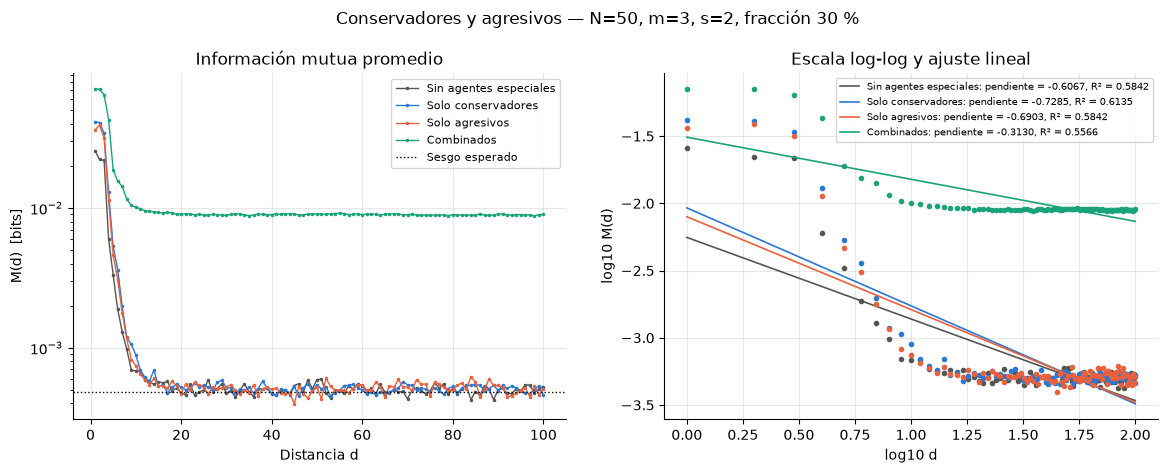

| Caso | Conservadores | Agresivos | Frecuencia de 0, 1, 2 | M(1) | Pendiente | R² | Éxito conservadores | Éxito agresivos | Éxito comunes |
|---|---|---|---|---|---|---|---|---|---|
| Sin agentes especiales | 0 | 0 | 0.335, 0.331, 0.335 | 2.57e-02 | -0.6067 | 0.5842 | -- | -- | 0.2926 |
| Solo conservadores | 15 | 0 | 0.359, 0.360, 0.282 | 4.14e-02 | -0.7285 | 0.6135 | 0.2474 | -- | 0.2987 |
| Solo agresivos | 0 | 15 | 0.363, 0.274, 0.363 | 3.63e-02 | -0.6903 | 0.5842 | -- | 0.2468 | 0.2988 |
| Combinados | 15 | 15 | 0.388, 0.305, 0.308 | 7.12e-02 | -0.3130 | 0.5566 | 0.2470 | 0.2471 | 0.3062 |

In [8]:
# ===== SECCION 2: M(d) y escala log-log =====
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
filas = []
for (clave, (nombre, nc, na)), color in zip(TIPOS_2.items(), [COLORES[5], COLORES[0], COLORES[1], COLORES[2]]):
    r = RESULTADOS["S2"][clave]
    media = r["Md"].mean(axis=0)
    ax1.plot(DISTANCIAS, media, ".-", color=color, ms=3, lw=1, label=nombre)
    aj = ajuste_loglog(DISTANCIAS, media)
    ax2.plot(aj["x"], aj["y"], "o", color=color, ms=3)
    ax2.plot(aj["x"], aj["y_ajuste"], "-", color=color, lw=1.2,
             label=f"{nombre}: pendiente = {aj['pendiente']:.4f}, R² = {aj['r2']:.4f}")
    e = r["exito"]
    texto = lambda v: "--" if np.isnan(v) else f"{v:.4f}"
    filas.append(f"| {nombre} | {nc} | {na} | {r['frec'][0]:.3f}, {r['frec'][1]:.3f}, {r['frec'][2]:.3f} | "
                 f"{media[0]:.2e} | {aj['pendiente']:.4f} | {aj['r2']:.4f} | {texto(e[0])} | {texto(e[1])} | {texto(e[2])} |")
ax1.axhline(sesgo_esperado(3, P2["T"]), color="k", ls=":", lw=1, label="Sesgo esperado")
ax1.set(yscale="log", xlabel="Distancia d", ylabel="M(d)  [bits]", title="Información mutua promedio")
ax1.legend(fontsize=8)
ax2.set(xlabel="log10 d", ylabel="log10 M(d)", title="Escala log-log y ajuste lineal")
ax2.legend(fontsize=7)
fig.suptitle(f"Conservadores y agresivos — N={P2['N']}, m={P2['m']}, s={P2['s']}, fracción {int(P2['fraccion'] * 100)} %", y=1.02)
plt.show()
display(Markdown("| Caso | Conservadores | Agresivos | Frecuencia de 0, 1, 2 | M(1) | Pendiente | R² | Éxito conservadores | Éxito agresivos | Éxito comunes |\n"
                 "|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(filas)))

**Qué se observa**

- **Solo conservadores y solo agresivos** se parecen mucho al caso sin agentes especiales: $M(d)$ sube un poco en las primeras distancias ($M(1)$ de 0.041 y 0.036 bits contra 0.026) y desde $d\approx 10$ cae al nivel del sesgo esperado. Las pendientes log-log son de $-0.73$ y $-0.69$, contra $-0.61$ sin especiales.
- **La opción forzada gana menos:** con conservadores, el 2 gana en el 28 % de los turnos; con agresivos, el 1 gana en el 27 %. Como esos agentes eligen esa opción más seguido, deja de ser la minoría.
- **Los agentes especiales aciertan menos** (0.247) que los comunes (0.299 a 0.306).
- **Combinados:** $M(d)$ no cae al sesgo, sino que se queda en una meseta de unos $9\times10^{-3}$ bits, por eso su recta log-log es mucho más plana (pendiente $-0.31$). Esa meseta viene casi toda de **una sola cadena** (la cadena 31), cuya $M(100)$ vale 0.84 bits: sin ella, el promedio para $d\ge 20$ baja a $5.6\times10^{-4}$ bits, como en los demás casos. No se investigó qué pasa en esa cadena (es uno de los puntos que están en pausa).

---
# Sección 3. Variación del número de agentes (fases 3 y 6)

**Pregunta:** ¿cambia la estructura de la serie al cambiar N, es decir, al cambiar $\gamma=K^m/N$?

Con m = 2, s = 3 y T = 6000 se recorren 11 de los 52 valores de N de la fase 6, elegidos para ver el cambio de régimen: de N = 5 ($\gamma=1.8$) a N = 7000 ($\gamma=0.0013$). La fase 3 hizo lo mismo con m = 3, s = 2 y N de 100 a 4000.

In [9]:
# ===== SECCION 3: simulacion =====
P3 = {"m": 2, "s": 3, "K": 3, "T": 6000}
LISTA_N_3 = [5, 11, 17, 19, 22, 25, 32, 50, 100, 1000, 7000]


def cadena_3(N, semilla):
    serie, exitos, conteos, _ = simular_con_puntaje(N, P3["m"], P3["s"], P3["K"], P3["T"], semilla, OPCION_VACIA_GANA)
    vacias = int((conteos == 0).any(axis=1).sum())
    return M_de_serie(serie, P3["K"]), C_de_serie(serie, P3["K"]), exitos.sum() / (N * P3["T"]), vacias


t0 = time.time()
orden = sorted(LISTA_N_3, reverse=True)          # los N grandes primero, para repartir mejor el trabajo
salida = correr_en_paralelo(cadena_3, [(N, int(sem)) for N in orden for sem in SEMILLAS])
RESULTADOS["S3"] = {}
for i, N in enumerate(orden):
    bloque = salida[i * N_CADENAS:(i + 1) * N_CADENAS]
    RESULTADOS["S3"][N] = {"Md": np.array([b[0] for b in bloque]), "C": np.array([b[1] for b in bloque]),
                           "exito": np.mean([b[2] for b in bloque]), "azar": exito_al_azar(N, P3["K"]),
                           "vacias": sum(b[3] for b in bloque)}
print(f"Seccion 3 lista en {time.time() - t0:.0f} s: {len(LISTA_N_3)} valores de N x {N_CADENAS} cadenas")

Seccion 3 lista en 83 s: 11 valores de N x 100 cadenas


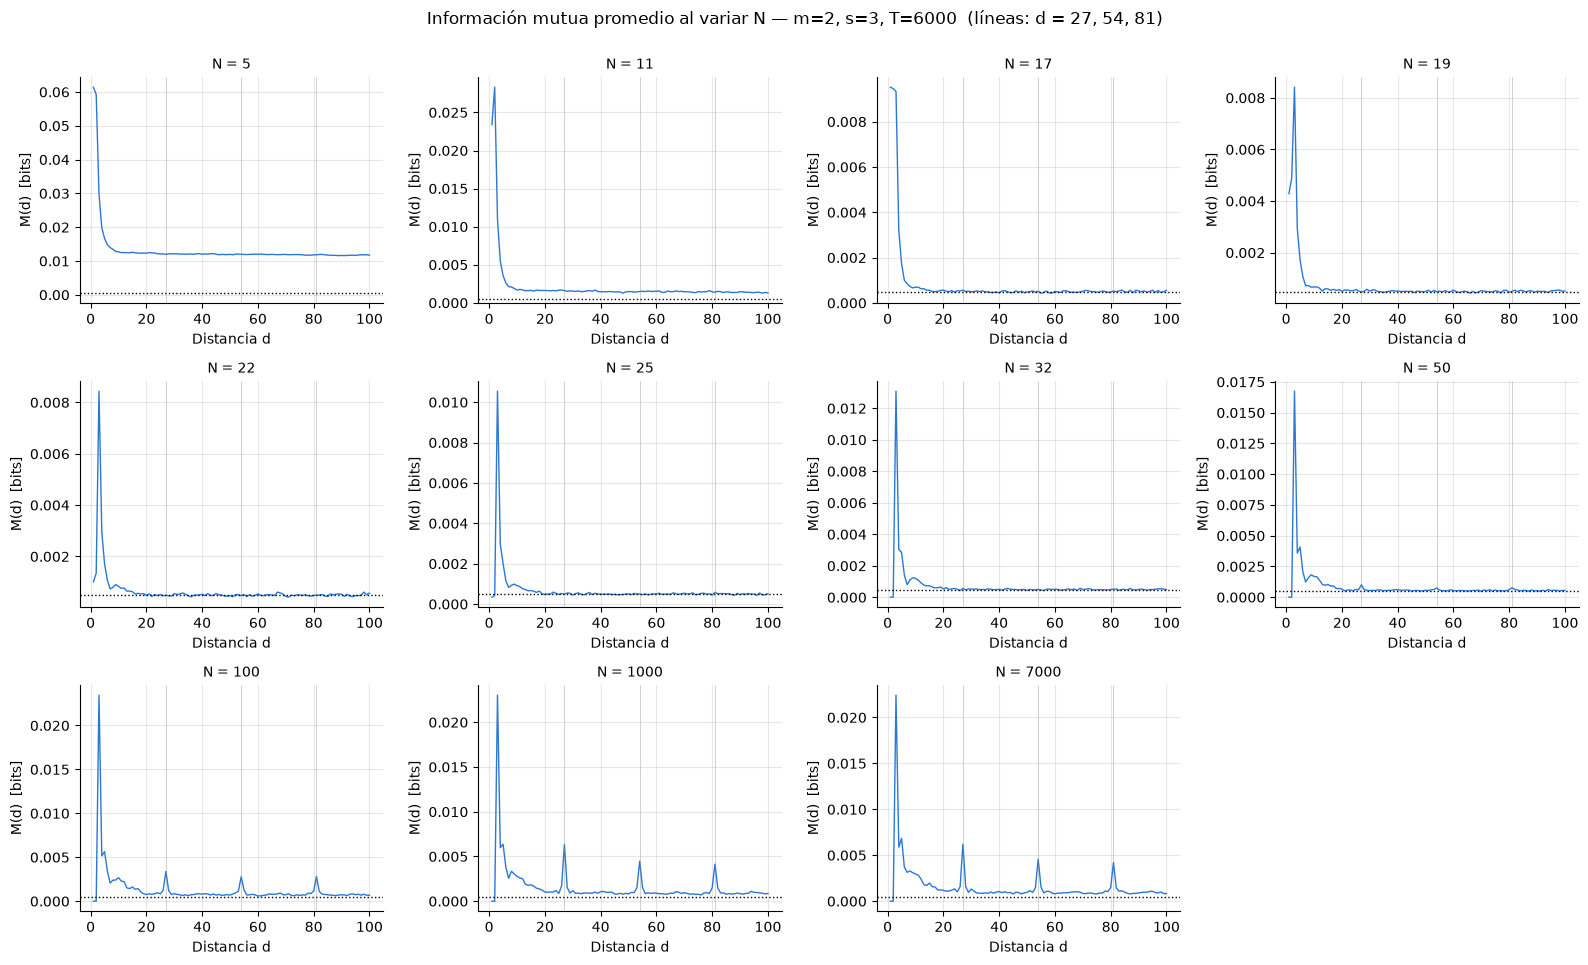

In [10]:
# ===== SECCION 3: M(d) promedio para cada N =====
filas_g = int(np.ceil(len(LISTA_N_3) / 4))
fig, ejes = plt.subplots(filas_g, 4, figsize=(16, 3.2 * filas_g))
for ax, N in zip(ejes.flat, LISTA_N_3):
    media = RESULTADOS["S3"][N]["Md"].mean(axis=0)
    ax.plot(DISTANCIAS, media, "-", color=COLORES[0], lw=1)
    ax.axhline(sesgo_esperado(3, P3["T"]), color="k", ls=":", lw=1)
    for d0 in (27, 54, 81):
        ax.axvline(d0, color="gray", lw=0.5, alpha=0.5)
    ax.set_title(f"N = {N}", fontsize=10)
    ax.set_xlabel("Distancia d")
    ax.set_ylabel("M(d)  [bits]")
for ax in list(ejes.flat)[len(LISTA_N_3):]:
    ax.axis("off")
fig.suptitle(f"Información mutua promedio al variar N — m={P3['m']}, s={P3['s']}, T={P3['T']}  (líneas: d = 27, 54, 81)", y=1.0)
fig.tight_layout()
plt.show()

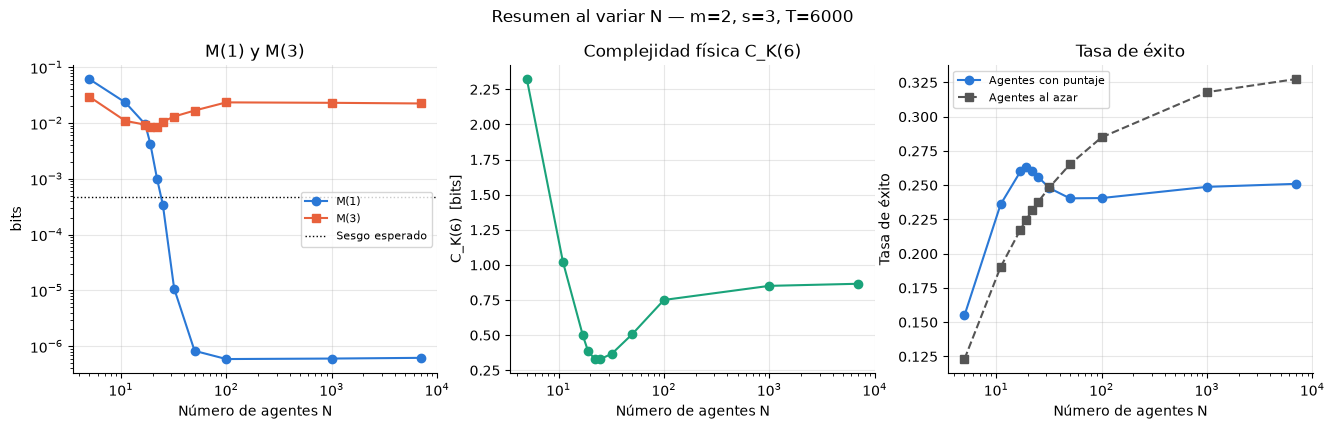

| N | γ | M(1) | M(3) | d del máximo | Contraste en d = 27 | C_K(6) | Éxito | Éxito al azar | Turnos con opción vacía |
|---|---|---|---|---|---|---|---|---|---|
| 5 | 1.8000 | 6.14e-02 | 2.97e-02 | 1 | 1.0 | 2.323 | 0.1550 | 0.1231 | 135147 |
| 11 | 0.8182 | 2.34e-02 | 1.09e-02 | 2 | 1.0 | 1.022 | 0.2359 | 0.1902 | 1181 |
| 17 | 0.5294 | 9.52e-03 | 9.33e-03 | 1 | 1.1 | 0.498 | 0.2601 | 0.2176 | 38 |
| 19 | 0.4737 | 4.29e-03 | 8.41e-03 | 3 | 0.9 | 0.389 | 0.2630 | 0.2243 | 28 |
| 22 | 0.4091 | 1.01e-03 | 8.44e-03 | 3 | 1.0 | 0.330 | 0.2606 | 0.2317 | 23 |
| 25 | 0.3600 | 3.42e-04 | 1.05e-02 | 3 | 1.0 | 0.330 | 0.2560 | 0.2378 | 34 |
| 32 | 0.2812 | 1.08e-05 | 1.31e-02 | 3 | 1.1 | 0.368 | 0.2479 | 0.2485 | 50 |
| 50 | 0.1800 | 8.24e-07 | 1.67e-02 | 3 | 1.7 | 0.507 | 0.2404 | 0.2652 | 73 |
| 100 | 0.0900 | 5.87e-07 | 2.35e-02 | 3 | 4.2 | 0.751 | 0.2406 | 0.2849 | 7 |
| 1000 | 0.0090 | 5.99e-07 | 2.30e-02 | 3 | 6.3 | 0.851 | 0.2488 | 0.3179 | 0 |
| 7000 | 0.0013 | 6.17e-07 | 2.24e-02 | 3 | 5.6 | 0.866 | 0.2510 | 0.3275 | 0 |

In [11]:
# ===== SECCION 3: resumen contra N =====
Ns = np.array(LISTA_N_3)
M1 = np.array([RESULTADOS["S3"][N]["Md"].mean(axis=0)[0] for N in Ns])
M3 = np.array([RESULTADOS["S3"][N]["Md"].mean(axis=0)[2] for N in Ns])
C6 = np.array([RESULTADOS["S3"][N]["C"].mean(axis=0)[5] for N in Ns])
exito = np.array([RESULTADOS["S3"][N]["exito"] for N in Ns])
azar = np.array([RESULTADOS["S3"][N]["azar"] for N in Ns])

fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
ejes[0].plot(Ns, M1, "o-", color=COLORES[0], label="M(1)")
ejes[0].plot(Ns, M3, "s-", color=COLORES[1], label="M(3)")
ejes[0].axhline(sesgo_esperado(3, P3["T"]), color="k", ls=":", lw=1, label="Sesgo esperado")
ejes[0].set(xscale="log", yscale="log", xlabel="Número de agentes N", ylabel="bits", title="M(1) y M(3)")
ejes[1].plot(Ns, C6, "o-", color=COLORES[2])
ejes[1].set(xscale="log", xlabel="Número de agentes N", ylabel="C_K(6)  [bits]", title="Complejidad física C_K(6)")
ejes[2].plot(Ns, exito, "o-", color=COLORES[0], label="Agentes con puntaje")
ejes[2].plot(Ns, azar, "s--", color=COLORES[5], label="Agentes al azar")
ejes[2].set(xscale="log", xlabel="Número de agentes N", ylabel="Tasa de éxito", title="Tasa de éxito")
for ax in ejes[[0, 2]]:
    ax.legend(fontsize=8)
fig.suptitle(f"Resumen al variar N — m={P3['m']}, s={P3['s']}, T={P3['T']}", y=1.02)
plt.show()

filas = []
for N, m1, m3, c6, ex, az in zip(Ns, M1, M3, C6, exito, azar):
    media = RESULTADOS["S3"][N]["Md"].mean(axis=0)
    filas.append(f"| {N} | {3 ** P3['m'] / N:.4f} | {m1:.2e} | {m3:.2e} | {int(np.argmax(media)) + 1} | "
                 f"{contraste(media, 27):.1f} | {c6:.3f} | {ex:.4f} | {az:.4f} | {RESULTADOS['S3'][N]['vacias']} |")
display(Markdown("| N | γ | M(1) | M(3) | d del máximo | Contraste en d = 27 | C_K(6) | Éxito | Éxito al azar | Turnos con opción vacía |\n"
                 "|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(filas)))

**Qué se observa**

- **Pocos agentes (N ≤ 17, $\gamma\ge 0.53$):** $M(1)$ es del orden de $10^{-2}$ bits y el máximo de $M(d)$ está en $d$ = 1 o 2. Con N = 5, $M(d)$ ni siquiera cae al sesgo: se queda en $1.2\times10^{-2}$ bits.
- **Cambio de régimen entre N ≈ 19 y N ≈ 32 ($\gamma\approx 0.47$ a $0.28$):** $M(1)$ cae de $4.3\times10^{-3}$ a $1.1\times10^{-5}$, y desde N ≈ 50 se queda en unos $6\times10^{-7}$ bits, casi 1000 veces por debajo del sesgo esperado. El máximo pasa a $d = 3 = m+1$.
- **Muchos agentes (N ≥ 100):** aparecen picos en $d$ = 27, 54 y 81, múltiplos de $3^{m+1}=27$ (contraste de 4.2 con N = 100 y de 5.6 a 6.3 con N = 1000 y 7000).
- **Complejidad:** $C_K(6)$ baja de 2.32 (N = 5) a un mínimo de 0.33 cerca de N = 22 a 25, y luego sube hasta unos 0.85.
- **Tasa de éxito:** los agentes con puntaje ganan más que al azar hasta N ≈ 25 y menos desde N ≈ 32.
- **Opciones vacías:** con pocos agentes sí ocurren (135 147 de 600 000 turnos con N = 5, 73 con N = 50, 7 con N = 100, ninguno con N = 1000 y 7000). Con la regla nueva estos resultados cambiarían.

---
# Sección 4. Variación de la memoria y comparación con el juego binario (fases 7 y 8)

**Pregunta:** ¿qué pasa al aumentar la memoria m con N fija? ¿Se comporta igual el juego binario (K = 2, sin abstención)?

N = 101, s = 2, T = 60000. El juego de tres decisiones va de m = 1 a 6 y el binario de m = 1 a 8 (el binario necesita memorias mayores para el mismo $\gamma$). Para comparar los dos alfabetos se usan las versiones normalizadas $c_K(6)$ y $M(1)/\log_2K$, contra $\gamma=K^m/N$. El juego binario usa el mismo motor con K = 2.

In [12]:
# ===== SECCION 4: simulacion (la mas larga, unos 11 minutos) =====
P4 = {"N": 101, "s": 2, "T": 60000}
LISTA_M_4 = {3: [1, 2, 3, 4, 5, 6], 2: [1, 2, 3, 4, 5, 6, 7, 8]}     # K: memorias


def cadena_4(K, m, semilla):
    serie = simular_con_puntaje(P4["N"], m, P4["s"], K, P4["T"], semilla, OPCION_VACIA_GANA)[0]
    return M_de_serie(serie, K), C_de_serie(serie, K)


t0 = time.time()
combinaciones = [(K, m) for K, ms in LISTA_M_4.items() for m in ms]
salida = correr_en_paralelo(cadena_4, [(K, m, int(sem)) for K, m in combinaciones for sem in SEMILLAS])
RESULTADOS["S4"] = {}
for i, (K, m) in enumerate(combinaciones):
    bloque = salida[i * N_CADENAS:(i + 1) * N_CADENAS]
    RESULTADOS["S4"][(K, m)] = {"Md": np.array([b[0] for b in bloque]), "C": np.array([b[1] for b in bloque])}
print(f"Seccion 4 lista en {(time.time() - t0) / 60:.1f} min: {len(combinaciones)} combinaciones x {N_CADENAS} cadenas")

Seccion 4 lista en 11.2 min: 14 combinaciones x 100 cadenas


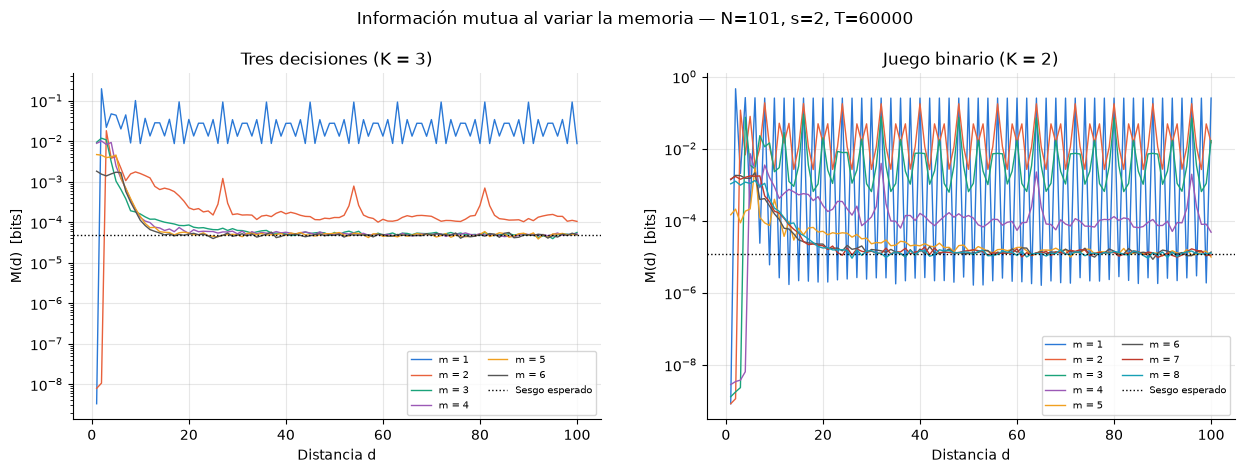

In [13]:
# ===== SECCION 4: M(d) para cada memoria =====
fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, K in zip(ejes, (3, 2)):
    for m, color in zip(LISTA_M_4[K], COLORES):
        ax.plot(DISTANCIAS, RESULTADOS["S4"][(K, m)]["Md"].mean(axis=0), "-", color=color, lw=1, label=f"m = {m}")
    ax.axhline(sesgo_esperado(K, P4["T"]), color="k", ls=":", lw=1, label="Sesgo esperado")
    ax.set(yscale="log", xlabel="Distancia d", ylabel="M(d)  [bits]",
           title="Tres decisiones (K = 3)" if K == 3 else "Juego binario (K = 2)")
    ax.legend(fontsize=7, ncol=2)
fig.suptitle(f"Información mutua al variar la memoria — N={P4['N']}, s={P4['s']}, T={P4['T']}", y=1.02)
plt.show()

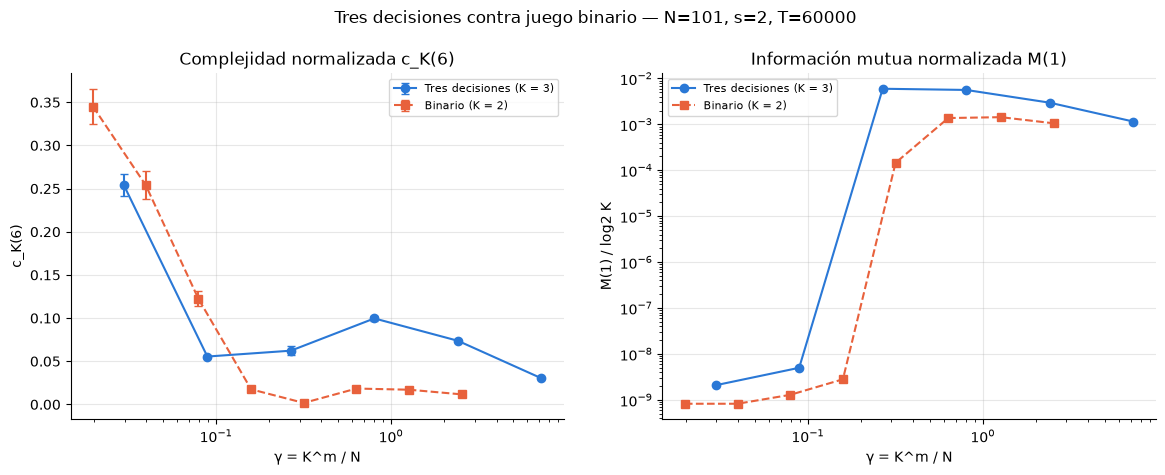

| K | m | γ | M(1) | M máxima | d del máximo | C_K(6) | c_K(6) | Pendiente log-log | R² |
|---|---|---|---|---|---|---|---|---|---|
| 3 | 1 | 0.0297 | 3.31e-09 | 1.99e-01 | 2 | 2.415 | 0.2539 | 0.5418 | 0.0825 |
| 3 | 2 | 0.0891 | 7.94e-09 | 1.83e-02 | 3 | 0.527 | 0.0555 | 0.0080 | 0.0000 |
| 3 | 3 | 0.2673 | 9.47e-03 | 1.19e-02 | 2 | 0.592 | 0.0623 | -1.0070 | 0.7501 |
| 3 | 4 | 0.8020 | 8.92e-03 | 1.02e-02 | 2 | 0.947 | 0.0996 | -1.0390 | 0.6918 |
| 3 | 5 | 2.4059 | 4.71e-03 | 4.71e-03 | 1 | 0.701 | 0.0737 | -0.9400 | 0.6561 |
| 3 | 6 | 7.2178 | 1.83e-03 | 1.83e-03 | 1 | 0.288 | 0.0303 | -0.7683 | 0.6359 |
| 2 | 1 | 0.0198 | 8.26e-10 | 4.62e-01 | 2 | 2.070 | 0.3450 | 0.1081 | 0.0003 |
| 2 | 2 | 0.0396 | 8.26e-10 | 1.88e-01 | 8 | 1.524 | 0.2540 | 1.2321 | 0.1773 |
| 2 | 3 | 0.0792 | 1.29e-09 | 9.07e-02 | 16 | 0.734 | 0.1224 | 1.3748 | 0.2019 |
| 2 | 4 | 0.1584 | 2.81e-09 | 7.29e-03 | 5 | 0.105 | 0.0175 | 0.8077 | 0.1022 |
| 2 | 5 | 0.3168 | 1.46e-04 | 2.94e-03 | 6 | 0.010 | 0.0017 | -0.8708 | 0.7664 |
| 2 | 6 | 0.6337 | 1.38e-03 | 2.14e-03 | 6 | 0.110 | 0.0184 | -1.2164 | 0.7659 |
| 2 | 7 | 1.2673 | 1.44e-03 | 1.75e-03 | 7 | 0.102 | 0.0170 | -1.2790 | 0.7601 |
| 2 | 8 | 2.5347 | 1.06e-03 | 1.31e-03 | 6 | 0.070 | 0.0116 | -1.2511 | 0.7633 |

In [14]:
# ===== SECCION 4: comparacion de los dos juegos contra gamma =====
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
filas = []
for K, marca, color in ((3, "o-", COLORES[0]), (2, "s--", COLORES[1])):
    gam, c6, c6_inf, c6_sup, m1 = [], [], [], [], []
    for m in LISTA_M_4[K]:
        r = RESULTADOS["S4"][(K, m)]
        c = r["C"][:, 5] / (6 * np.log2(K))                    # c_K(6) de cada cadena
        media, inf, sup = promedio_ic(c[:, None])
        Md = r["Md"].mean(axis=0)
        aj = ajuste_loglog(DISTANCIAS, Md)
        gam.append(K ** m / P4["N"]); c6.append(media[0]); c6_inf.append(inf[0]); c6_sup.append(sup[0])
        m1.append(Md[0] / np.log2(K))
        filas.append(f"| {K} | {m} | {K ** m / P4['N']:.4f} | {Md[0]:.2e} | {Md.max():.2e} | {int(np.argmax(Md)) + 1} | "
                     f"{r['C'].mean(axis=0)[5]:.3f} | {media[0]:.4f} | {aj['pendiente']:.4f} | {aj['r2']:.4f} |")
    nombre = "Tres decisiones (K = 3)" if K == 3 else "Binario (K = 2)"
    ejes[0].errorbar(gam, c6, yerr=[np.array(c6) - c6_inf, np.array(c6_sup) - c6], fmt=marca, color=color, capsize=3, label=nombre)
    ejes[1].plot(gam, m1, marca, color=color, label=nombre)
ejes[0].set(xscale="log", xlabel="γ = K^m / N", ylabel="c_K(6)", title="Complejidad normalizada c_K(6)")
ejes[1].set(xscale="log", yscale="log", xlabel="γ = K^m / N", ylabel="M(1) / log2 K", title="Información mutua normalizada M(1)")
for ax in ejes:
    ax.legend(fontsize=8)
fig.suptitle(f"Tres decisiones contra juego binario — N={P4['N']}, s={P4['s']}, T={P4['T']}", y=1.02)
plt.show()
display(Markdown("| K | m | γ | M(1) | M máxima | d del máximo | C_K(6) | c_K(6) | Pendiente log-log | R² |\n"
                 "|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(filas)))

**Qué se observa**

- **Tres decisiones: la forma cambia entre m = 2 y m = 3** ($\gamma$ = 0.089 a 0.267). Con m ≤ 2, $M(1)$ vale unos $10^{-8}$ bits, el máximo está en $d = m+1$ y hay periodicidades (picos en 27, 54 y 81 con m = 2). Desde m = 3, $M(1)$ salta a unos $10^{-2}$ bits y $M(d)$ es casi plana hasta $d\approx m$ y luego cae.
- **Juego binario: la forma cambia entre m = 4 y m = 6** ($\gamma$ = 0.16 a 0.63), con m = 5 como caso intermedio. Antes del cambio hay picos en múltiplos de $2^{m+1}$ (8 y 16 con m = 2 y 3).
- **El ajuste log-log** solo describe la curva después del cambio: pendientes de $-0.77$ a $-1.04$ con tres decisiones y de $-0.87$ a $-1.28$ en el binario, con $R^2$ de 0.64 a 0.77. Antes del cambio, $R^2$ es menor que 0.21.
- **Comparación contra $\gamma$:** las dos curvas de $M(1)/\log_2K$ tienen la misma forma (muy baja y luego un salto), pero el salto ocurre en distinto $\gamma$. Después del cambio, el juego de tres decisiones tiene más complejidad normalizada que el binario: $c_K(6)$ de 0.03 a 0.10 contra 0.002 a 0.018. Las curvas no se enciman.
- La validación del juego binario contra la literatura ($\sigma^2/N$ contra $z$, fase 8) se cumple solo en parte y no se incluye aquí; queda pendiente.

---
# Sección 5. Precios y hechos estilizados (fase 9)

**Pregunta:** si se construye un precio con los conteos de cada turno, ¿se parece a un mercado real?

Con N = 10000, s = 2 y T = 6000 se comparan dos casos de la fase 9:

- **Caso A:** m = 2, sin puntaje (los agentes usan sus estrategias al azar).
- **Caso F:** m = 5, con puntaje (el caso con colas más anchas, el que se le envió al Dr. Mansilla).

Con los conteos $N_0$ (compran) y $N_1$ (venden) de cada turno se construyen los tres precios. Las medidas se calculan después de un burn-in de 1000 turnos. Se buscan dos **hechos estilizados** de los mercados reales: **colas anchas** en la distribución de los rendimientos (curtosis positiva, exponente de cola chico) y **agrupamiento de la volatilidad** (la autocorrelación de $|r_t|$ decae lentamente). También se codifica cada precio en binario (1 si sube, 0 si baja) y se ajusta $C(l)=\beta l^{\alpha}$, como en Mansilla (Physica A 301, 2001).

La "cadena destacada" de cada caso es la de mayor recorrido del precio con exceso de demanda después del burn-in.

In [15]:
# ===== SECCION 5: simulacion y analisis =====
P5 = {"N": 10000, "s": 2, "K": 3, "T": 6000, "burn_in": 1000}
CASOS_5 = {"A": ("Caso A: m = 2, sin puntaje", 2, False), "F": ("Caso F: m = 5, con puntaje", 5, True)}
PRECIOS = {"mansilla": "Mansilla", "exceso": "Exceso de demanda", "cociente": "Cociente"}


def cadena_5(m, puntaje, semilla):
    N, s, K, T = P5["N"], P5["s"], P5["K"], P5["T"]
    if puntaje:
        return simular_con_puntaje(N, m, s, K, T, semilla, OPCION_VACIA_GANA)[2]
    return simular_sin_recompensa(N, m, s, K, T, semilla, OPCION_VACIA_GANA)[1]


def analizar_5(conteos):
    """Hechos estilizados y C(l) binaria de los tres precios, con burn-in."""
    N0, N1 = conteos[:, 0].astype(np.int64), conteos[:, 1].astype(np.int64)
    salida = {}
    for precio in PRECIOS:
        r, signo = rendimientos_y_signo(precio, N0, N1, P5["N"])
        r, signo = r[P5["burn_in"]:], signo[P5["burn_in"]:]
        binaria = (signo[signo != 0] > 0).astype(np.int64)
        salida[precio] = {"r": r, "curtosis": curtosis(r), "cola": exponente_cola(r),
                          "acf": autocorrelacion(np.abs(r)), "C_bin": C_de_serie(binaria, 2, l_max=8)}
    return salida


t0 = time.time()
RESULTADOS["S5"] = {}
for caso, (nombre, m, puntaje) in CASOS_5.items():
    conteos = correr_en_paralelo(cadena_5, [(m, puntaje, int(sem)) for sem in SEMILLAS])
    analisis = correr_en_paralelo(analizar_5, [(c,) for c in conteos])
    exceso = [np.concatenate([[0.0], np.cumsum(a["exceso"]["r"])]) for a in analisis]
    recorrido = [e.max() - e.min() for e in exceso]
    RESULTADOS["S5"][caso] = {"conteos": conteos, "analisis": analisis, "destacada": int(np.argmax(recorrido)),
                              "vacias": int(sum((c == 0).any(axis=1).sum() for c in conteos))}
    print(f"  {nombre}: listo ({time.time() - t0:.0f} s)")
print(f"Seccion 5 lista en {time.time() - t0:.0f} s")

  Caso A: m = 2, sin puntaje: listo (29 s)


  Caso F: m = 5, con puntaje: listo (119 s)
Seccion 5 lista en 119 s


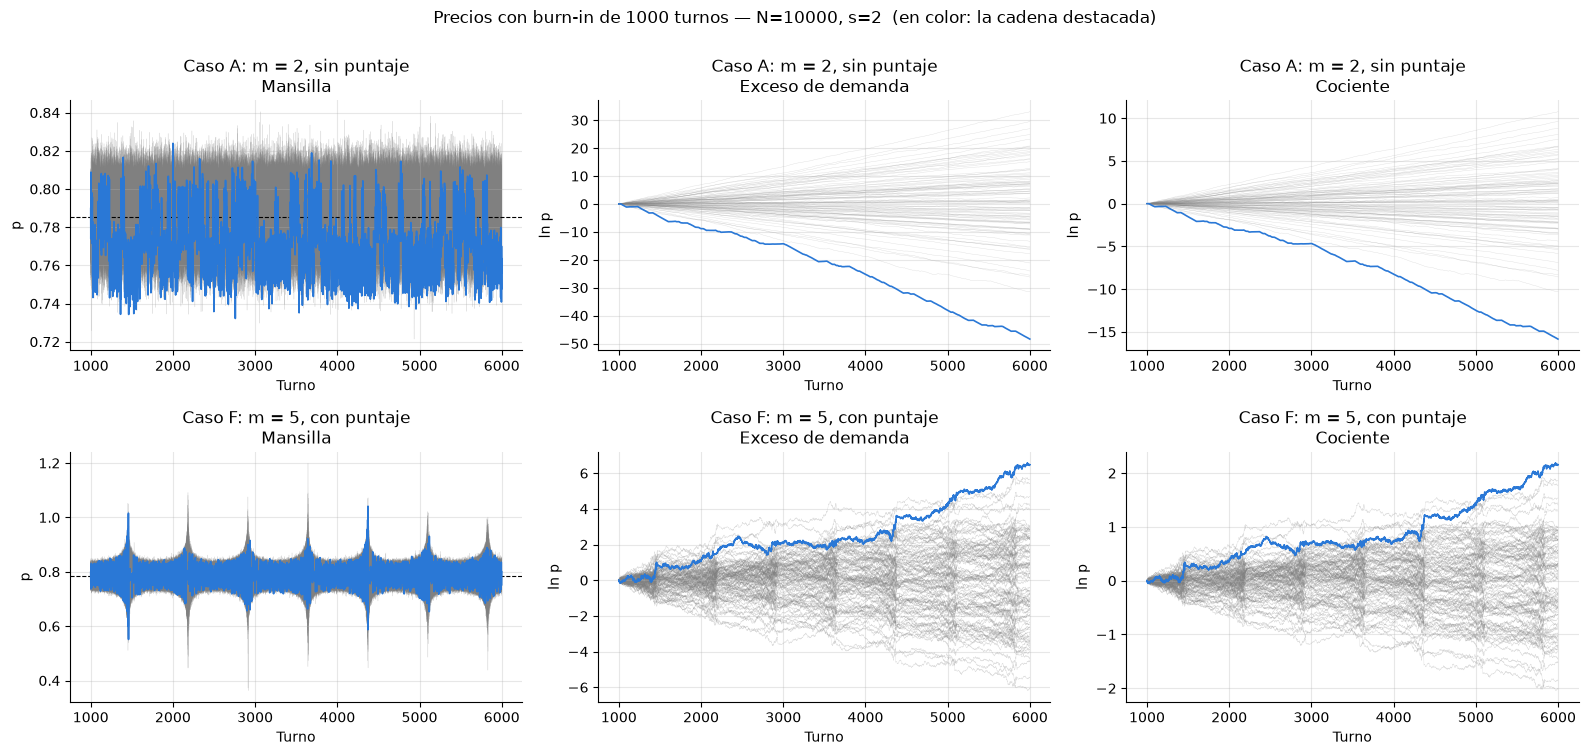

In [16]:
# ===== SECCION 5: los tres precios (100 cadenas en gris y la destacada en color) =====
b = P5["burn_in"]
turnos = np.arange(b, P5["T"])
fig, ejes = plt.subplots(2, 3, figsize=(16, 7.5))
for fila, (caso, (nombre, m, _)) in enumerate(CASOS_5.items()):
    r5 = RESULTADOS["S5"][caso]
    dest = r5["destacada"]
    for col, precio in enumerate(PRECIOS):
        ax = ejes[fila, col]
        for c in range(N_CADENAS):
            if precio == "mansilla":
                y = precio_mansilla(r5["conteos"][c][b:, 0].astype(float), r5["conteos"][c][b:, 1].astype(float))
                x = turnos
            else:
                y = np.cumsum(r5["analisis"][c][precio]["r"])
                x = turnos
            ax.plot(x, y, color=COLORES[0] if c == dest else "gray",
                    lw=1.2 if c == dest else 0.3, alpha=1 if c == dest else 0.25, zorder=3 if c == dest else 1)
        if precio == "mansilla":
            ax.axhline(np.pi / 4, color="k", ls="--", lw=0.8)
        ax.set(xlabel="Turno", ylabel="p" if precio == "mansilla" else "ln p",
               title=f"{nombre}\n{PRECIOS[precio]}")
fig.suptitle(f"Precios con burn-in de {b} turnos — N={P5['N']}, s={P5['s']}  (en color: la cadena destacada)", y=1.0)
fig.tight_layout()
plt.show()

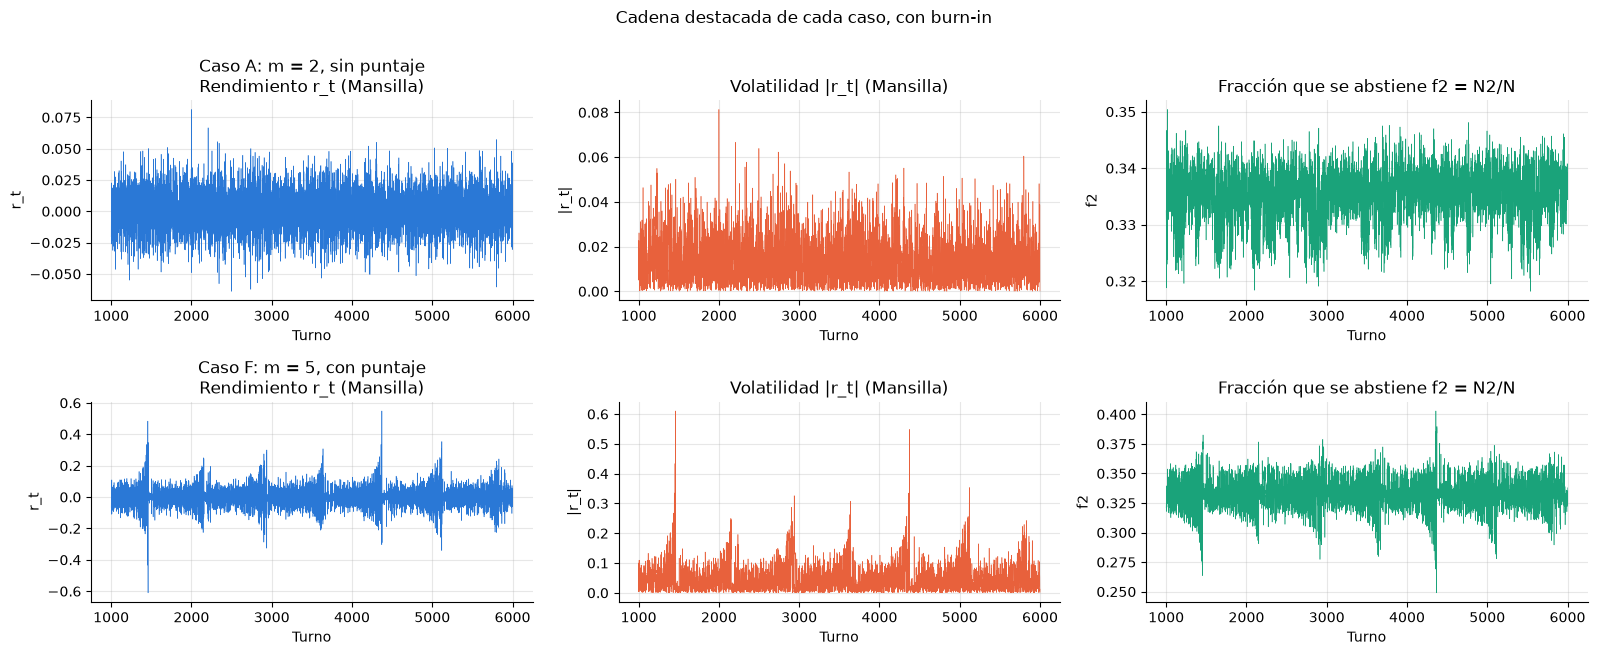

In [17]:
# ===== SECCION 5: rendimientos, volatilidad y abstencion de la cadena destacada =====
b = P5["burn_in"]
turnos = np.arange(b, P5["T"])
fig, ejes = plt.subplots(2, 3, figsize=(16, 6.5))
for fila, (caso, (nombre, m, _)) in enumerate(CASOS_5.items()):
    r5 = RESULTADOS["S5"][caso]
    dest = r5["destacada"]
    r = r5["analisis"][dest]["mansilla"]["r"]
    f2 = r5["conteos"][dest][b:, 2] / P5["N"]
    ejes[fila, 0].plot(turnos[1:] if len(r) < len(turnos) else turnos, r, lw=0.4, color=COLORES[0])
    ejes[fila, 1].plot(turnos[1:] if len(r) < len(turnos) else turnos, np.abs(r), lw=0.4, color=COLORES[1])
    ejes[fila, 2].plot(turnos, f2, lw=0.4, color=COLORES[2])
    ejes[fila, 0].set(title=f"{nombre}\nRendimiento r_t (Mansilla)", xlabel="Turno", ylabel="r_t")
    ejes[fila, 1].set(title="Volatilidad |r_t| (Mansilla)", xlabel="Turno", ylabel="|r_t|")
    ejes[fila, 2].set(title="Fracción que se abstiene f2 = N2/N", xlabel="Turno", ylabel="f2")
fig.suptitle("Cadena destacada de cada caso, con burn-in", y=1.0)
fig.tight_layout()
plt.show()

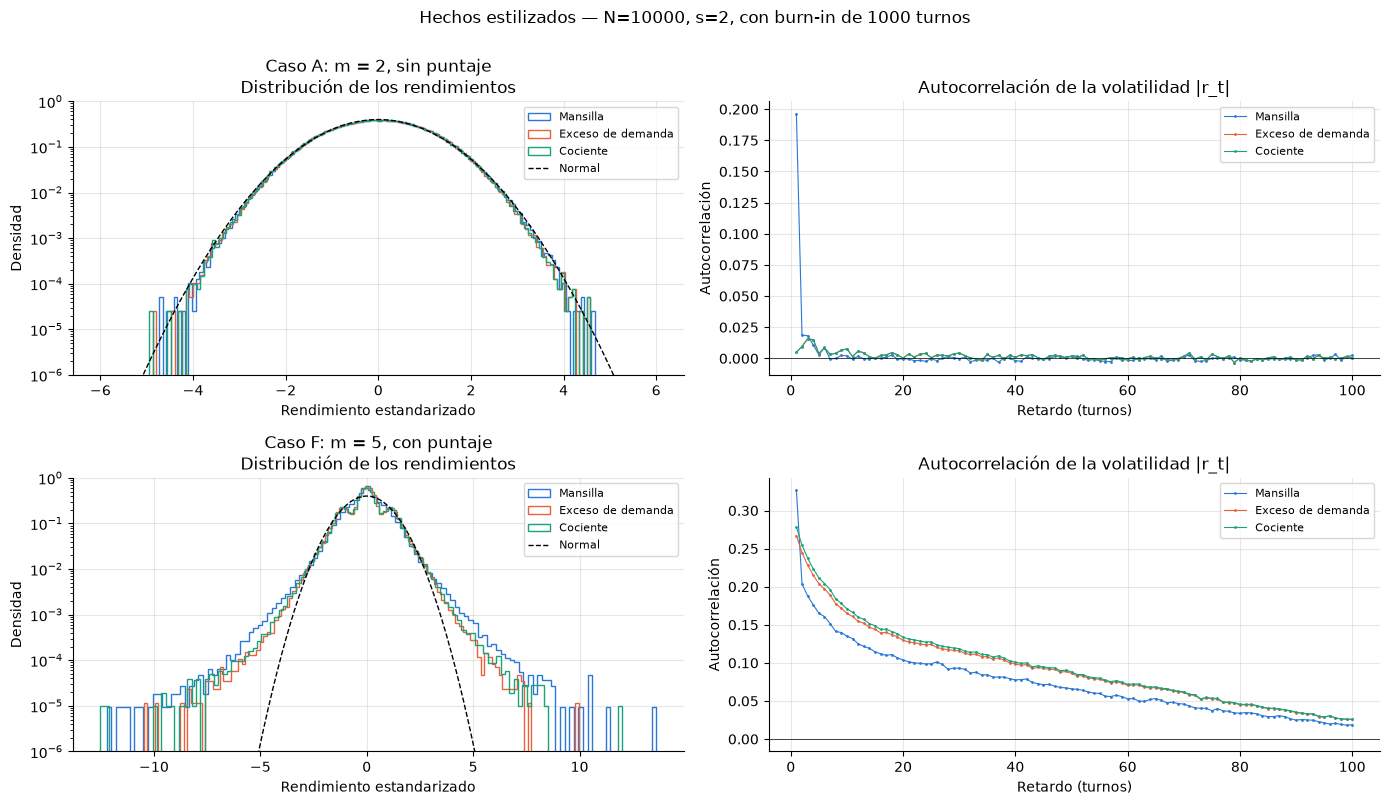

Exponente de la autocorrelación: menos la pendiente log-log, solo con retardos de valor positivo. α: exponente de C(l) = β l^α de la serie binaria (1 = sube, 0 = baja), con l = 2 a 8.

| Caso | Precio | Curtosis | Exponente de la cola | acf(1) de abs(r) | Exponente de la acf | R² acf | α de C(l) binaria | R² |
|---|---|---|---|---|---|---|---|---|
| A | Mansilla | -0.084 | 6.31 | 0.196 | 0.844 | 0.328 | 1.590 | 0.9924 |
| A | Exceso de demanda | -0.140 | 6.43 | 0.005 | 0.612 | 0.286 | 1.457 | 0.9974 |
| A | Cociente | -0.138 | 6.43 | 0.005 | 0.621 | 0.308 | 1.457 | 0.9974 |
| F | Mansilla | 3.649 | 3.53 | 0.327 | 0.605 | 0.826 | 1.510 | 0.9938 |
| F | Exceso de demanda | 1.406 | 4.46 | 0.267 | 0.554 | 0.803 | 3.529 | 0.9695 |
| F | Cociente | 1.926 | 4.25 | 0.278 | 0.564 | 0.804 | 3.529 | 0.9695 |

Turnos con una opcion vacia: {'A': 0, 'F': 0}


In [18]:
# ===== SECCION 5: hechos estilizados (promedio de 100 cadenas) =====
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
retardos = np.arange(1, 101)
filas = []
for fila, (caso, (nombre, m, _)) in enumerate(CASOS_5.items()):
    analisis = RESULTADOS["S5"][caso]["analisis"]
    # distribucion de los rendimientos estandarizados (las 100 cadenas juntas)
    for precio, color in zip(PRECIOS, COLORES):
        z = np.concatenate([(a[precio]["r"] - a[precio]["r"].mean()) / a[precio]["r"].std() for a in analisis])
        ejes[fila, 0].hist(z, bins=120, density=True, histtype="step", color=color, label=PRECIOS[precio])
        acf = np.nanmean([a[precio]["acf"] for a in analisis], axis=0)
        aj_acf = ajuste_loglog(retardos, acf)
        ejes[fila, 1].plot(retardos, acf, ".-", ms=2, lw=0.8, color=color, label=PRECIOS[precio])
        aj_C = ajuste_potencia(np.arange(1, 9), np.mean([a[precio]["C_bin"] for a in analisis], axis=0))
        filas.append(f"| {caso} | {PRECIOS[precio]} | {np.nanmean([a[precio]['curtosis'] for a in analisis]):.3f} | "
                     f"{np.nanmean([a[precio]['cola'] for a in analisis]):.2f} | {acf[0]:.3f} | "
                     f"{-aj_acf['pendiente']:.3f} | {aj_acf['r2']:.3f} | {aj_C['alpha']:.3f} | {aj_C['r2']:.4f} |")
    zz = np.linspace(-6, 6, 300)
    ejes[fila, 0].plot(zz, np.exp(-zz ** 2 / 2) / np.sqrt(2 * np.pi), "k--", lw=1, label="Normal")
    ejes[fila, 0].set(yscale="log", ylim=(1e-6, 1), xlabel="Rendimiento estandarizado", ylabel="Densidad",
                      title=f"{nombre}\nDistribución de los rendimientos")
    ejes[fila, 1].axhline(0, color="k", lw=0.5)
    ejes[fila, 1].set(xlabel="Retardo (turnos)", ylabel="Autocorrelación", title="Autocorrelación de la volatilidad |r_t|")
    for ax in ejes[fila]:
        ax.legend(fontsize=8)
fig.suptitle(f"Hechos estilizados — N={P5['N']}, s={P5['s']}, con burn-in de {P5['burn_in']} turnos", y=1.0)
fig.tight_layout()
plt.show()
display(Markdown("Exponente de la autocorrelación: menos la pendiente log-log, solo con retardos de valor positivo. "
                 "α: exponente de C(l) = β l^α de la serie binaria (1 = sube, 0 = baja), con l = 2 a 8.\n\n"
                 "| Caso | Precio | Curtosis | Exponente de la cola | acf(1) de abs(r) | Exponente de la acf | R² acf | α de C(l) binaria | R² |\n"
                 "|---|---|---|---|---|---|---|---|---|\n" + "\n".join(filas)))
print("Turnos con una opcion vacia:", {c: RESULTADOS["S5"][c]["vacias"] for c in CASOS_5})

**Qué se observa**

- **Caso A (sin puntaje):** los rendimientos son prácticamente normales (curtosis de $-0.08$ a $-0.14$, exponente de cola de 6.3 a 6.4) y la volatilidad no se agrupa (autocorrelación de $|r_t|$ con retardo 1 de 0.005 en los precios acumulados). Los precios acumulados se van casi en línea recta: cada cadena tiene un sesgo casi fijo entre compradores y vendedores.
- **Caso F (m = 5, con puntaje): aparecen los dos hechos estilizados.** Colas anchas (curtosis de 1.4 a 3.65, exponente de cola de 3.5 a 4.5) y agrupamiento de la volatilidad: la autocorrelación de $|r_t|$ vale de 0.27 a 0.33 con retardo 1, sigue positiva en los 100 retardos y decae como una ley de potencia con exponente de 0.55 a 0.61 ($R^2$ ≈ 0.8).
- **Ráfagas periódicas en el caso F:** la volatilidad y el precio de Mansilla tienen ráfagas separadas por unos 730 turnos, cerca de $3^6 = 729$, y en ellas la fracción que se abstiene oscila más. Esto se ve a ojo en las gráficas; no se midió.
- En el precio de Mansilla, la autocorrelación con retardo 1 es de 0.2 aun sin puntaje. Probablemente se debe a que $r_t$ y $r_{t+1}$ comparten el valor $p_t$ (interpretación no comprobada).
- **Serie binaria:** con el precio de Mansilla, $\alpha\approx 1.5$ a 1.6 en los dos casos. Con los precios acumulados, $\alpha$ = 1.46 sin puntaje y 3.53 con puntaje. El artículo de Mansilla (2001) reporta 2.1 a 3.8 con precios reales.
- No hubo turnos con una opción vacía. La fase 9 completa tiene 7 casos (m = 2 a 6) y también el caso N = 101; aquí solo están los dos más contrastantes.

---
# Sección 6. Búsqueda de la fase gaseosa (fase 11)

**Pregunta (del Dr. Mansilla):** las corridas anteriores con muchos agentes muestran picos periódicos en $M(d)$ en $d$ = 27, 54 y 81. ¿Desaparecen si el número de agentes supera al número de estrategias posibles (la "fase gaseosa")?

Con m = 2, s = 2 y tres decisiones hay $K^{K^m}=3^9=19683$ estrategias posibles. La fase 11 llegó hasta un millón de agentes (8 horas de cálculo). Aquí se usa una versión reducida con tres valores: N = 101, 1001 y 19684 (justo por encima del número de estrategias). Criterio acordado: hay pico si el **contraste** ($M(d_0)$ entre la mediana de sus 14 vecinos) es al menos 2.

In [19]:
# ===== SECCION 6: simulacion =====
P6 = {"m": 2, "s": 2, "K": 3, "T": 6000}
LISTA_N_6 = [101, 1001, 19684]
N_ESTRATEGIAS = P6["K"] ** (P6["K"] ** P6["m"])     # 3^9 = 19683


def cadena_6(N, semilla):
    serie, exitos, conteos, _ = simular_con_puntaje(N, P6["m"], P6["s"], P6["K"], P6["T"], semilla, OPCION_VACIA_GANA)
    return M_de_serie(serie, P6["K"]), C_de_serie(serie, P6["K"]), exitos.sum() / (N * P6["T"]), int((conteos == 0).any(axis=1).sum())


t0 = time.time()
orden = sorted(LISTA_N_6, reverse=True)
salida = correr_en_paralelo(cadena_6, [(N, int(sem)) for N in orden for sem in SEMILLAS])
RESULTADOS["S6"] = {}
for i, N in enumerate(orden):
    bloque = salida[i * N_CADENAS:(i + 1) * N_CADENAS]
    RESULTADOS["S6"][N] = {"Md": np.array([b[0] for b in bloque]), "C": np.array([b[1] for b in bloque]),
                           "exito": np.mean([b[2] for b in bloque]), "azar": exito_al_azar(N, P6["K"]),
                           "vacias": sum(b[3] for b in bloque)}
print(f"Seccion 6 lista en {time.time() - t0:.0f} s; estrategias posibles: {N_ESTRATEGIAS}")

Seccion 6 lista en 228 s; estrategias posibles: 19683


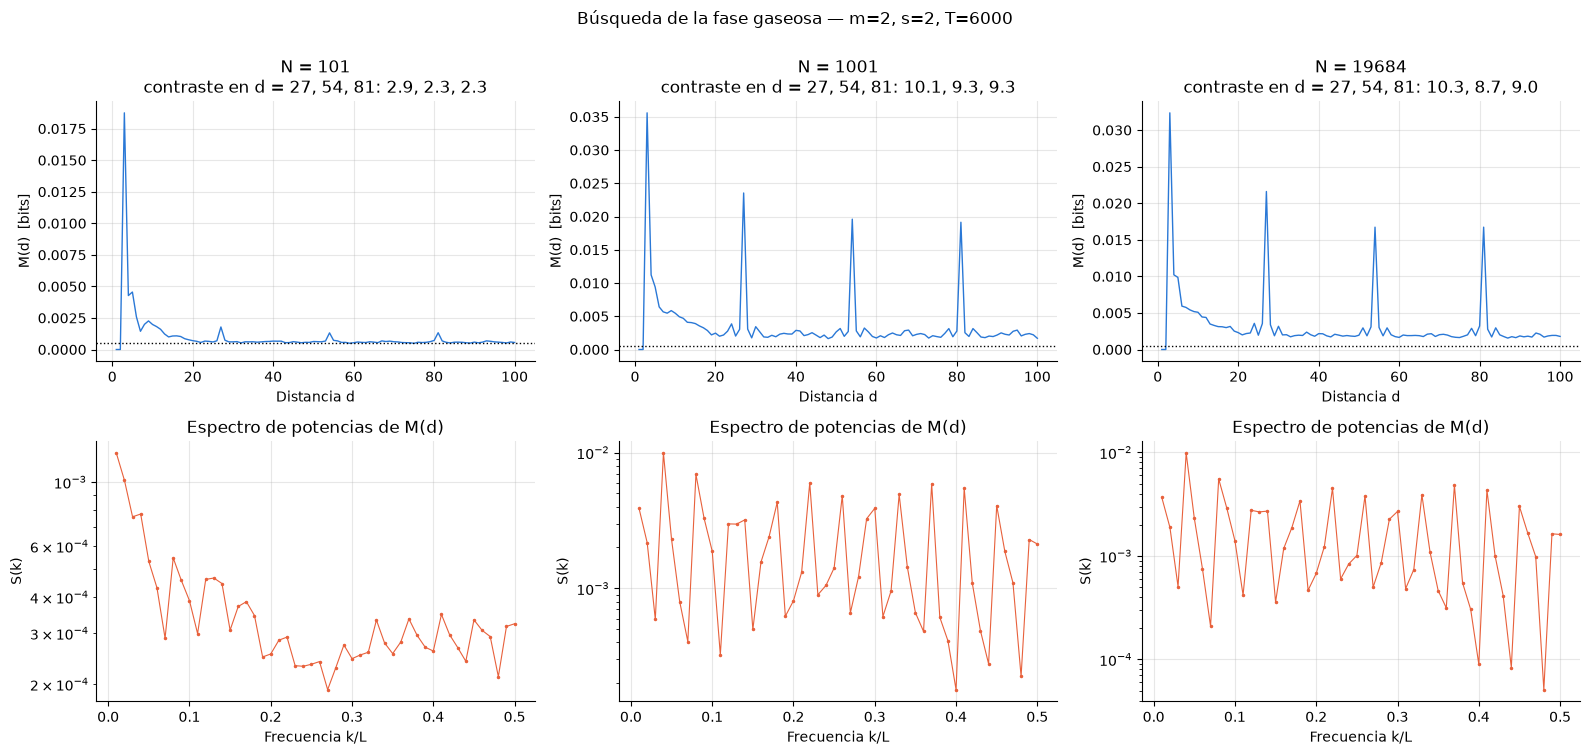

| N | N·s / estrategias | Éxito | Éxito al azar | M(1) | M(3) | Contraste 27 / 54 / 81 | C_K(6) | ¿Hay picos? | Turnos con opción vacía |
|---|---|---|---|---|---|---|---|---|---|
| 101 | 0.01 | 0.2760 | 0.2852 | 9.45e-07 | 1.88e-02 | 2.9 / 2.3 / 2.3 | 0.608 | sí | 0 |
| 1001 | 0.10 | 0.2756 | 0.3179 | 6.02e-07 | 3.56e-02 | 10.1 / 9.3 / 9.3 | 1.235 | sí | 0 |
| 19684 | 2.00 | 0.2781 | 0.3298 | 6.13e-07 | 3.24e-02 | 10.3 / 8.7 / 9.0 | 1.223 | sí | 0 |

In [20]:
# ===== SECCION 6: M(d), espectro y contraste =====
fig, ejes = plt.subplots(2, len(LISTA_N_6), figsize=(16, 7.5))
filas = []
for col, N in enumerate(LISTA_N_6):
    r = RESULTADOS["S6"][N]
    Md = r["Md"].mean(axis=0)
    cont = [contraste(Md, d0) for d0 in (27, 54, 81)]
    ejes[0, col].plot(DISTANCIAS, Md, "-", color=COLORES[0], lw=1)
    ejes[0, col].axhline(sesgo_esperado(3, P6["T"]), color="k", ls=":", lw=1)
    ejes[0, col].set(title=f"N = {N}\ncontraste en d = 27, 54, 81: {cont[0]:.1f}, {cont[1]:.1f}, {cont[2]:.1f}",
                     xlabel="Distancia d", ylabel="M(d)  [bits]")
    f, S = espectro_potencias(Md)
    ejes[1, col].plot(f, S, ".-", color=COLORES[1], ms=3, lw=0.8)
    ejes[1, col].set(yscale="log", title="Espectro de potencias de M(d)", xlabel="Frecuencia k/L", ylabel="S(k)")
    filas.append(f"| {N} | {N * P6['s'] / N_ESTRATEGIAS:.2f} | {r['exito']:.4f} | {r['azar']:.4f} | {Md[0]:.2e} | {Md[2]:.2e} | "
                 f"{cont[0]:.1f} / {cont[1]:.1f} / {cont[2]:.1f} | {r['C'].mean(axis=0)[5]:.3f} | "
                 f"{'sí' if max(cont) >= 2 else 'no'} | {r['vacias']} |")
fig.suptitle(f"Búsqueda de la fase gaseosa — m={P6['m']}, s={P6['s']}, T={P6['T']}", y=1.0)
fig.tight_layout()
plt.show()
display(Markdown("| N | N·s / estrategias | Éxito | Éxito al azar | M(1) | M(3) | Contraste 27 / 54 / 81 | C_K(6) | ¿Hay picos? | Turnos con opción vacía |\n"
                 "|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(filas)))

**Qué se observa**

- **No aparece la fase gaseosa.** Los picos en $d$ = 27, 54 y 81 siguen con N = 19684, por encima del número de estrategias posibles, con un contraste de 8.7 a 10.3. En la fase 11 completa, con N hasta un millón de agentes, el contraste siguió entre 8 y 10.
- **Las curvas casi no cambian desde N = 1001.** Los picos son más débiles con pocos agentes (contraste de 2.3 a 2.9 con N = 101), no con muchos.
- **$M(1)$ y $M(2)$ valen casi cero** (unos $6\times10^{-7}$ bits), unas 800 veces por debajo del sesgo de una serie al azar. El primer valor grande es $M(3)$.
- **Los agentes ganan menos que al azar** (0.278 contra 0.330 con N = 19684).
- El espectro de potencias muestra picos regulares, no un espectro continuo.
- **Interpretación sin comprobar:** $27 = 3\times3^2 = K\cdot K^m$. En el juego binario la literatura describe una dinámica de periodo $2\cdot2^m$ justamente cuando hay muchos agentes, así que esta periodicidad podría ser la marca de esa zona y no algo que desaparezca al agregar agentes. Conviene consultarlo con el Dr. Mansilla.

---
# Sección 7. Ajuste de la función de Hill (fase 12)

**Pregunta (encargo del Dr. Mansilla):** en escala log-log, $M(d)$ suele tener forma de "Z". ¿La describe la función de Hill, y qué parámetros cambian con m y s?

Cinco casos con puntaje, N = 101, T = 60000: (m, s) = (1, 0), (1, 1), (2, 0), (2, 1) y (2, 2). Con s = 0 los agentes eligen al azar, así que m no interviene y (1, 0) y (2, 0) son la misma simulación; solo cambia el rango del segundo ajuste. Con s = 1 cada agente tiene una sola estrategia y el puntaje no tiene efecto. Se hacen dos ajustes de Hill por caso: con todos los $d$ y con $d\ge m+1$, más la recta log-log.

In [21]:
# ===== SECCION 7: simulacion =====
P7 = {"N": 101, "K": 3, "T": 60000, "m_azar": 3}       # m_azar: memoria que lleva la simulacion al azar (no la usa)
CASOS_7 = [(1, 0), (1, 1), (2, 0), (2, 1), (2, 2)]
SIMULACIONES_7 = ["azar", (1, 1), (2, 1), (2, 2)]          # s = 0 se simula una sola vez


def cadena_7(clave, semilla):
    N, K, T = P7["N"], P7["K"], P7["T"]
    if clave == "azar":
        serie = simular_ingenuos(N, P7["m_azar"], K, T, semilla, OPCION_VACIA_GANA)
    else:
        m, s = clave
        serie = simular_con_puntaje(N, m, s, K, T, semilla, OPCION_VACIA_GANA)[0]
    return M_de_serie(serie, K)


t0 = time.time()
salida = correr_en_paralelo(cadena_7, [(clave, int(sem)) for clave in SIMULACIONES_7 for sem in SEMILLAS])
datos = {clave: np.array(salida[i * N_CADENAS:(i + 1) * N_CADENAS]) for i, clave in enumerate(SIMULACIONES_7)}
RESULTADOS["S7"] = {}
for m, s in CASOS_7:
    Md = datos["azar" if s == 0 else (m, s)].mean(axis=0)
    ajustes = {}
    for nombre, d_min in (("todos los d", 1), (f"d ≥ {m + 1}", m + 1)):
        sel = (DISTANCIAS >= d_min) & (Md > 0)
        x, y = np.log10(DISTANCIAS[sel]), np.log10(Md[sel])
        ajustes[nombre] = {"x": x, "y": y, "r": ajustar_hill(x, y)}
    RESULTADOS["S7"][(m, s)] = {"Md": Md, "ajustes": ajustes, "recta": ajuste_loglog(DISTANCIAS, Md)}
print(f"Seccion 7 lista en {time.time() - t0:.0f} s")

Seccion 7 lista en 292 s


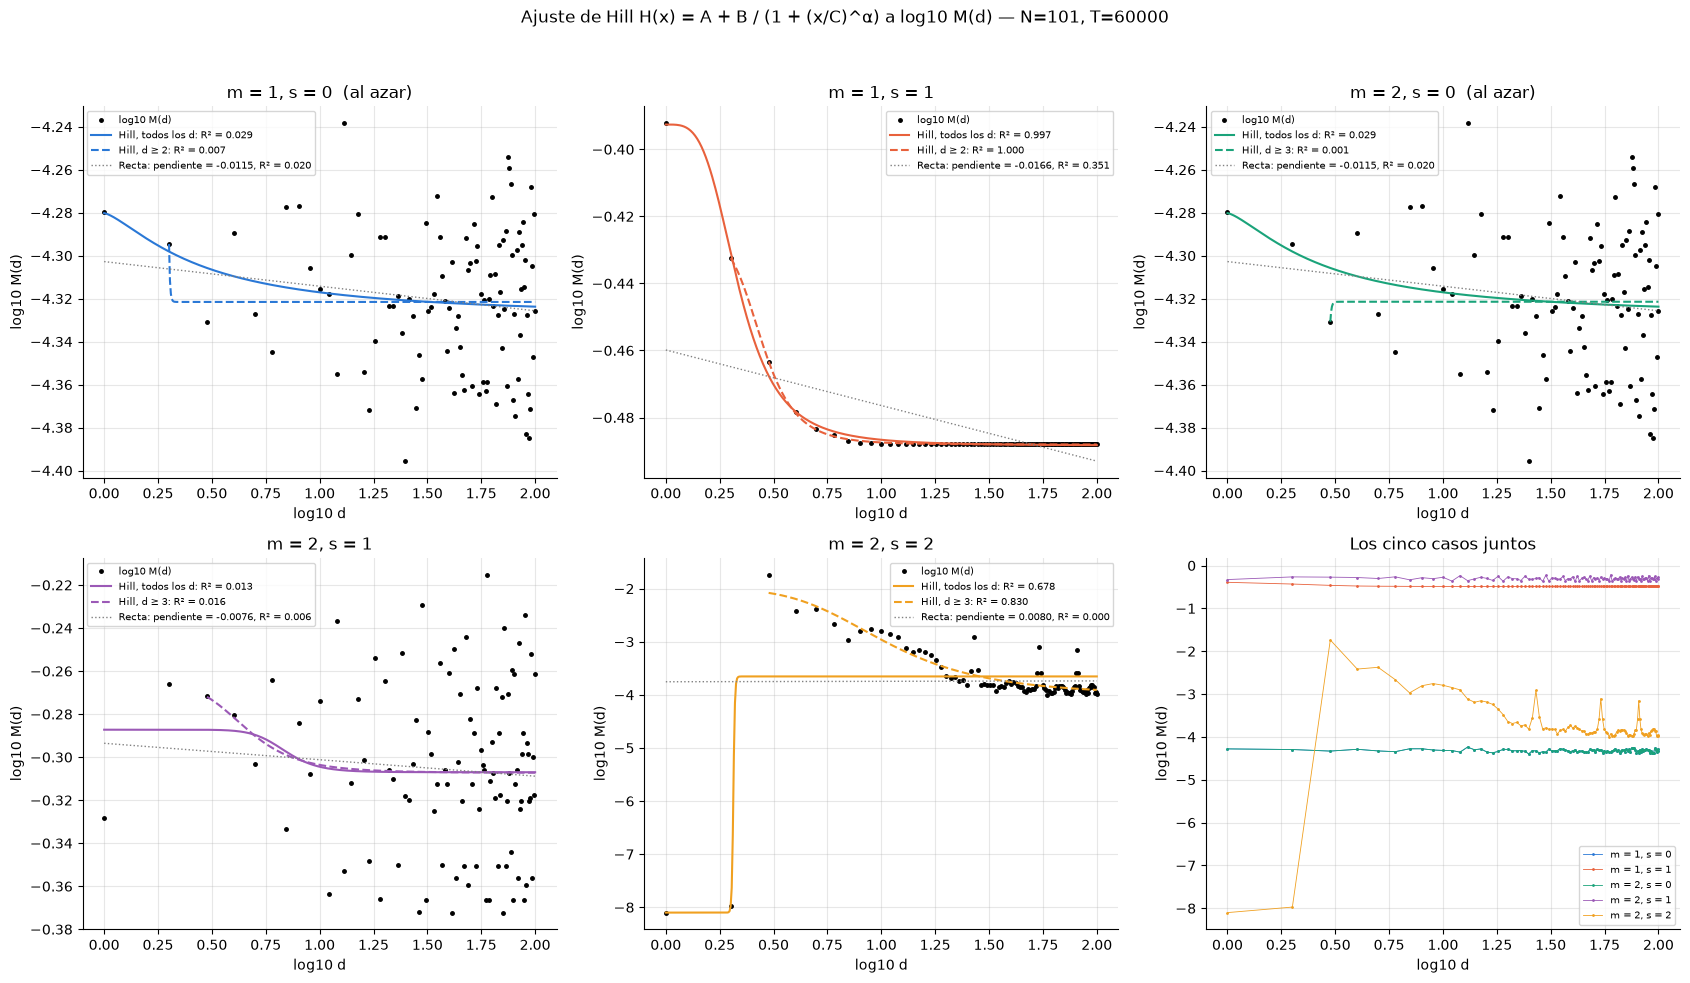

| m | s | Rango del ajuste | n | A | B | C | α | R² | RMSE | Arranques que convergieron | Avisos del script |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 0 | todos los d | 100 | -4.329 | 0.049 | 0.450 | 1.38 | 0.0292 | 0.0322 | 24/30 | -- |
| 1 | 0 | d ≥ 2 | 99 | -4.322 | 6.292e+08 | 0.214 | 70.31 | 0.0068 | 0.0325 | 3/30 | débil |
| 1 | 1 | todos los d | 100 | -0.488 | 0.096 | 0.337 | 3.66 | 0.9971 | 0.0006 | 30/30 | -- |
| 1 | 1 | d ≥ 2 | 99 | -0.488 | 0.062 | 0.445 | 5.69 | 0.9995 | 0.0001 | 30/30 | -- |
| 2 | 0 | todos los d | 100 | -4.329 | 0.049 | 0.450 | 1.38 | 0.0292 | 0.0322 | 24/30 | -- |
| 2 | 0 | d ≥ 3 | 98 | -4.321 | -0.553 | 0.456 | 90.41 | 0.0008 | 0.0326 | 2/30 | débil |
| 2 | 1 | todos los d | 100 | -0.307 | 0.020 | 0.839 | 10.91 | 0.0133 | 0.0385 | 30/30 | -- |
| 2 | 1 | d ≥ 3 | 98 | -0.307 | 0.041 | 0.658 | 5.53 | 0.0155 | 0.0386 | 30/30 | -- |
| 2 | 2 | todos los d | 100 | -3.653 | -4.447 | 0.313 | 87.72 | 0.6779 | 0.4230 | 30/30 | débil |
| 2 | 2 | d ≥ 3 | 98 | -4.014 | 2.007 | 1.023 | 4.30 | 0.8301 | 0.1761 | 30/30 | -- |

In [22]:
# ===== SECCION 7: M(d) en log-log con los ajustes de Hill =====
fig, ejes = plt.subplots(2, 3, figsize=(17, 9.5))
filas = []
for ax, (m, s), color in zip(ejes.flat, CASOS_7, COLORES):
    r7 = RESULTADOS["S7"][(m, s)]
    x_todos = np.log10(DISTANCIAS[r7["Md"] > 0])
    ax.plot(x_todos, np.log10(r7["Md"][r7["Md"] > 0]), "o", color="k", ms=2.5, label="log10 M(d)")
    for (nombre, aj), estilo in zip(r7["ajustes"].items(), ("-", "--")):
        c = aj["r"]["coeficientes"]
        xx = np.linspace(aj["x"].min(), aj["x"].max(), 400)
        ax.plot(xx, hill(xx, c["A"], c["B"], c["C"], c["alfa"]), estilo, color=color, lw=1.5,
                label=f"Hill, {nombre}: R² = {aj['r']['R2']:.3f}")
        avisos = []
        if any("límite" in a for a in aj["r"]["avisos"]):
            avisos.append("límite")
        if any("débilmente" in a for a in aj["r"]["avisos"]):
            avisos.append("débil")
        B = f"{c['B']:.3e}" if abs(c["B"]) >= 1000 else f"{c['B']:.3f}"
        filas.append(f"| {m} | {s} | {nombre} | {aj['r']['n']} | {c['A']:.3f} | {B} | {c['C']:.3f} | {c['alfa']:.2f} | "
                     f"{aj['r']['R2']:.4f} | {aj['r']['RMSE']:.4f} | {aj['r']['inicios_convergentes']}/{aj['r']['inicios']} | "
                     f"{', '.join(avisos) if avisos else '--'} |")
    ax.plot(r7["recta"]["x"], r7["recta"]["y_ajuste"], ":", color="gray", lw=1,
            label=f"Recta: pendiente = {r7['recta']['pendiente']:.4f}, R² = {r7['recta']['r2']:.3f}")
    ax.set(title=f"m = {m}, s = {s}" + ("  (al azar)" if s == 0 else ""), xlabel="log10 d", ylabel="log10 M(d)")
    ax.legend(fontsize=7, loc="best")
ax = ejes.flat[5]                                  # ultimo panel: los cinco casos juntos
for (m, s), color in zip(CASOS_7, COLORES):
    Md = RESULTADOS["S7"][(m, s)]["Md"]
    ax.plot(np.log10(DISTANCIAS[Md > 0]), np.log10(Md[Md > 0]), ".-", ms=2, lw=0.6, color=color, label=f"m = {m}, s = {s}")
ax.set(title="Los cinco casos juntos", xlabel="log10 d", ylabel="log10 M(d)")
ax.legend(fontsize=7)
fig.suptitle(f"Ajuste de Hill H(x) = A + B / (1 + (x/C)^α) a log10 M(d) — N={P7['N']}, T={P7['T']}", y=1.03)
fig.tight_layout()
plt.show()
display(Markdown("| m | s | Rango del ajuste | n | A | B | C | α | R² | RMSE | Arranques que convergieron | Avisos del script |\n"
                 "|---|---|---|---|---|---|---|---|---|---|---|---|\n" + "\n".join(filas)))

**Qué se observa**

**La función de Hill describe la forma solo en 2 de los 5 casos:**

- **m = 1, s = 1: sí** ($R^2$ = 0.997 con todos los $d$ y 0.9995 desde $d$ = 2). $M(d)$ baja y luego se queda plana, que es la forma de Hill, aunque la caída es pequeña: de 0.41 a 0.33 bits.
- **m = 2, s = 2: solo desde $d$ = 3** ($R^2$ = 0.83). Con todos los $d$ ($R^2$ = 0.68), el ajuste se dedica al salto entre $M(1), M(2)\approx 10^{-8}$ y $M(3)\approx 2\times10^{-2}$: $\alpha$ sale 88, cerca del límite de 100, y el script avisa que los parámetros están mal determinados.
- **s = 0 (al azar): no** ($R^2$ ≤ 0.03). La curva es plana, en el nivel del sesgo esperado ($4.8\times10^{-5}$ bits). Los ajustes desde $d\ge m+1$ están degenerados (convergieron 3 y 2 de 30 arranques).
- **m = 2, s = 1: no** ($R^2\approx 0.01$). $M(d)$ es grande (0.47 a 0.61 bits) y oscila sin decaer.
- Las cadenas con s = 1 son muy distintas entre sí: unas son casi periódicas y otras casi al azar, y el promedio las mezcla.

En resumen: cuando $M(d)$ decae, Hill describe bien esa caída; cuando no decae, no hay forma que describir.

---
# Resumen de resultados

| Sección | Resultado principal |
|---|---|
| 1. Tres tipos de agentes | Las estrategias le dan memoria a la serie: $M(d)$ decae con $d$ (pendiente log-log $-0.99$ sin puntaje y $-0.61$ con puntaje); con agentes al azar es plana. |
| 2. Conservadores y agresivos | Solo conservadores o solo agresivos cambian poco a $M(d)$. En combinados, la meseta de $M(d)$ viene casi toda de una sola cadena. |
| 3. Variación de N | Cambio de régimen entre N ≈ 19 y 32 ($\gamma\approx 0.47$ a 0.28): $M(1)$ cae casi a cero, el máximo pasa a $d = m+1$ y aparecen picos en múltiplos de 27. |
| 4. Variación de m y juego binario | Los dos juegos tienen un cambio del mismo tipo, en distinto $\gamma$. Después del cambio, el juego de tres decisiones tiene más complejidad normalizada que el binario. |
| 5. Precios | Con puntaje y memoria intermedia (m = 5) aparecen colas anchas y agrupamiento de la volatilidad; sin puntaje, no. |
| 6. Fase gaseosa | No apareció: los picos en 27, 54 y 81 siguen aun con más agentes que estrategias posibles. |
| 7. Función de Hill | Describe la caída de $M(d)$ cuando la hay (2 de 5 casos); no describe las curvas planas u oscilantes. |

**Lo que no está en este notebook** (está en los notebooks y reportes de cada fase): la validación del juego binario ($\sigma^2/N$ contra $z$, fase 8), la variación de N con m = 3 (fase 3), las 54 pendientes de conservadores y agresivos (fase 4), la codificación ternaria y los 7 casos de precios (fase 9) y la fase 11 completa hasta un millón de agentes.

**Pendientes:** confirmar con el Dr. Mansilla la regla de la opción vacía; validación del juego binario; comparación con índices reales (NASDAQ, IPC); burbujas con LPPL; la función que describe la forma de $M(d)$ y por qué el caso combinados de la fase 4 sale más plano.